In [1]:
import os
# https://stackoverflow.com/questions/20554074/sklearn-omp-error-15-initializing-libiomp5md-dll-but-found-mk2iomp5md-dll-a
os.environ["KMP_DUPLICATE_LIB_OK"]="TRUE"

import torch
from torch import nn

import numpy as np
import normflows as nf

import tqdm

import matplotlib
import matplotlib.pyplot as plt

from multires_hash_encoding import MultiresEncoding, MultiresEncodingConfig

In [2]:
import importlib
import sys
from pathlib import Path
if os.name == 'nt':
    sys.path.append(os.getcwd() + "\\..\\src")    
else:
    sys.path.append(os.getcwd() + "/../src")
print(sys.path)

['p:\\Programs\\miniconda3\\envs\\master-pytorch\\python313.zip', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\DLLs', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\Lib', 'p:\\Programs\\miniconda3\\envs\\master-pytorch', '', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\Lib\\site-packages', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\Lib\\site-packages\\win32', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\Lib\\site-packages\\win32\\lib', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\Lib\\site-packages\\Pythonwin', 'd:\\Studium\\Masters\\Masters\\scripts\\..\\src']


In [3]:
class OneBlobEncoding(nn.Module):
    def __init__(self, in_features, K):
        super().__init__()
        self.in_features = in_features
        self.K = K
        self.encoding_size = in_features * K

    def forward(self, x):
        sigma = 1.0 / self.K
        kernel = torch.arange(1 / (2 * self.K), 1, sigma)
        
        sqrt_2_pi = 2.50662827463
        values = 1 / (sqrt_2_pi * sigma) * torch.exp(-(x.unsqueeze(-1) - kernel)**2 / (2 * sigma**2))

        return values.flatten(start_dim=-2)


torch.Size([10000, 64])


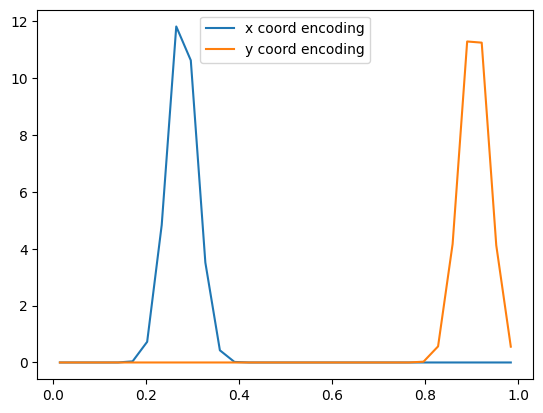

In [4]:
x = torch.rand((10000, 2))
K = 32

sigma = 1.0 / K
kernel = torch.arange(1 / (2 * K), 1, sigma)

enc = OneBlobEncoding(2, K)
values = enc(x)

print(values.shape)

# plt.plot(torch.cat((kernel, kernel + 1)), reshaped[2])

vis_samples = 500

plt.plot(kernel, values[vis_samples, :K], label='x coord encoding')
plt.plot(kernel, values[vis_samples, K:2 * K], label='y coord encoding')
plt.legend()

In [3]:
import norm_flow
import GMM

importlib.reload(norm_flow)
importlib.reload(GMM)


from norm_flow import Uniform
import GMM

In [34]:
def init_identity(m):
    if isinstance(m, nn.Linear):
        # Fill with identity if possible
        with torch.no_grad():
            m.weight.zero_()
            for i in range(min(m.in_features, m.out_features)):
                m.weight[i, i] = 1.0
            if m.bias is not None:
                m.bias.zero_()

def init_zero(m):
    if isinstance(m, nn.Linear):
        # Fill with identity if possible
        with torch.no_grad():
            m.weight.zero_()
            if m.bias is not None:
                m.bias.zero_()


class Layer(nn.Module):
    def __init__(self, channels_in, channels_out, activation = nn.ReLU(), is_residual = False):
        super().__init__()
        self.channels_in = channels_in
        self.channels_out = channels_out
        self.lin_forward = nn.Linear(self.channels_in, self.channels_out)
        # torch.nn.init.xavier_uniform(self.lin_forward.weight)
        self.activation = activation

        self.is_residual = is_residual

    def forward(self, x):
        if not self.is_residual or True:
            return self.activation(self.lin_forward(x))
        else: 
            return self.activation(self.lin_forward(x)) + x


class MLP(nn.Module):
    """
    Represents the actual neural network part of a model. 
    Does not hold the extra information required to correctly operate it (e.g. input distribtion, domain, etc.)

    
    Attributes
    ---------
    layers : [int]
        Array of ints specifying hidden layers. N entries will result in N-1 layers.
    activation_function : Callable
        Activation function to be used in the network, as of yet not configurable by layer
    """

    def __init__(self,
                 in_features,
                 out_features,
                 hidden_layers, 
                 activation_function = nn.ReLU(),
                 is_residual = False):
        super().__init__()
        if len(hidden_layers) < 1:
            raise Exception("Need at least 2 entries in layer description to create MLP")
                
        self.in_proj = Layer(channels_in=in_features, channels_out=hidden_layers[0], activation=activation_function)
        
        self.net = nn.Sequential(*[
            Layer(layer_in, layer_out, activation_function, is_residual=False) for layer_in, layer_out in zip(hidden_layers, hidden_layers[1:])
        ])

        self.out_proj = nn.Linear(in_features=hidden_layers[-1], out_features=out_features)

        self.is_residual = is_residual
        if self.is_residual:
            self.residual_scaling = nn.Parameter(torch.ones(in_features))

    def forward(self, x):
        if self.is_residual:
            return self.residual_scaling * x + self.out_proj(self.net(self.in_proj(x)))
        else:
            return self.out_proj(self.net(self.in_proj(x)))
    
    def input_shape(self):
        return self.net[0].channels_in
    

# Class taken and adapted from the source code of https://github.com/VincentStimper/normalizing-flows
class ImagePrior(nn.Module):
    """
    Intensities of an image determine probability density of prior
    """

    def __init__(self, 
                 image, 
                 domain = [[0, 1], [0, 1]], 
                 eps=1.0e-10, 
                 dtype=torch.float32, 
                 add_flat_gaussian: bool = True, 
                 normalize = True):
        """Constructor

        Args:
          image: image as np matrix
          index_0_1: Whether to index from [0, 1]^2 instead of [-1, 1]^2
          eps: small value to add to image to avoid log(0) problems
        """
        super().__init__()

        if add_flat_gaussian:
            xx, yy = torch.meshgrid(torch.linspace(-1, 1, image.shape[0]), torch.linspace(-1, 1, image.shape[1]))
            zz = torch.cat([xx.unsqueeze(2), yy.unsqueeze(2)], 2).view(-1, 2)

            sigma = 10
            dist = torch.distributions.multivariate_normal.MultivariateNormal(torch.zeros(2), torch.eye(2) * sigma)

            log_probs = dist.log_prob(zz).view(*xx.shape)
            probs = torch.exp(log_probs)

            image_tens = torch.tensor(image, dtype=dtype) + probs
        else:
            image_tens = torch.tensor(image, dtype=dtype)

        if normalize:
            image_ = (image_tens / image_tens.sum() + eps)[None, None, ..., ...]
        else:
            image_ = image_tens[None, None, ..., ...]
        self.image_dims = image_.shape
        
        self.register_buffer("domain", torch.as_tensor(domain))
        self.register_buffer("log_eps", torch.log(torch.tensor(eps, dtype=dtype)))
        self.register_buffer(
            "density", image_ / torch.sum(image_)
        )

    def from_domain(self, x):
        x = (x - self.domain[:, 0]) / (self.domain[:, 1] - self.domain[:, 0])
        return x * 2 - 1
    
    def to_domain(self, x):
        x = (x + 1) / 2
        return x * (self.domain[:, 1] - self.domain[:, 0])
        

    def log_prob(self, z):
        """
        Args:
          z: value or batch of latent variable

        Returns:
          log probability of the distribution for z
        """

        # Map into [-1, 1] when user wants to index in [0, 1]
        z = self.from_domain(z)

        z = z[None, None, ..., ...]

        log_probs = torch.log(torch.nn.functional.grid_sample(self.density, z, mode='bilinear').view(-1))

        return torch.where(torch.isinf(log_probs), self.log_eps, log_probs)
    
    def prob(self, z):
        """
        Args:
          z: value or batch of latent variable

        Returns:
          probability of the distribution for z
        """

        # Map into [-1, 1] when user wants to index in [0, 1]
        z = self.from_domain(z)

        z = z[None, None, ..., ...]

        return torch.nn.functional.grid_sample(self.density, z).view(-1)

In [5]:
def computeJacDets(func, input, loop_batch = False):
    if loop_batch:
        Js = []
        for i in range(input.shape[0]):
            Ji = torch.autograd.functional.jacobian(func, input[i].unsqueeze(0), vectorize=True).squeeze(0)
            Js.append(Ji.squeeze(0))
        Js = torch.stack(Js, dim=0)
    else :
        Js = torch.autograd.functional.jacobian(func, input, vectorize=True, create_graph=True)
    idx = torch.arange(input.shape[0], device=input.device)
    Js = Js[idx, :, idx, :]
    return torch.det(Js)


def vis2dModel(model,
               target, 
               prior,
               device,
               grid_size = 100,
               num_test_samples = 1000, 
               start = -2, 
               end = 2, 
               num_samples = 10000,
               colormap = 'jet'):

    step = (end - start) / num_test_samples

    xx, yy = torch.meshgrid(torch.linspace(-1, 1, grid_size), torch.linspace(-1, 1, grid_size))
    zz = torch.cat([xx.unsqueeze(2), yy.unsqueeze(2)], 2).view(-1, 2)
    zz = zz.to(device)
    log_prob = target.log_prob(zz).to('cpu').view(*xx.shape)
    prob = torch.exp(log_prob)

    q=prior.log_prob(zz).exp().cpu().view(*xx.shape)
    
    jac = torch.func.vmap(torch.func.jacrev(model, chunk_size=1))

    jacobians = jac(zz)
    abs_dets = torch.det(jacobians).clamp(min = 1e-4)

    # dets = computeJacDets(model, zz, loop_batch=True)
    # abs_dets = dets.clamp(min = 1e-4)


    transform = model(zz)
    reconstruced_prior = abs_dets * target.log_prob(transform).exp()


     
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 6))

    ax1.pcolormesh(xx, yy, prob.cpu().detach(), cmap=colormap)
    ax1.set_title("target")
    
    ax2.pcolormesh(xx, yy, q, cmap=colormap)
    ax2.set_title("prior")

    # ax3.pcolormesh(xx, yy, abs_dets.cpu().detach().view(*xx.shape), cmap=colormap)
    # ax3.set_title("abs dets")

    # ax3.pcolormesh(xx, yy, reconstruced_prior.cpu().detach().view(*xx.shape), cmap=colormap)
    # ax3.set_title("reconstructed prior")
            
    x = prior.sample(num_samples)
    pred_samples = model(x).cpu().detach().numpy()
    ax3.hist2d(pred_samples[:, 0], pred_samples[:, 1], bins=100, range=[[-1.0, 1.0], [-1.0, 1.0]], cmap=colormap, norm="linear")
    ax3.set_title("drawn samples")
    
    plt.show()


def vis2dModel_loss(model, target, prior, device, num_samples = 10000, bins = 50, colormap = 'jet'):
    x = prior.sample(num_samples)
    pred_samples = model(x).cpu().detach().numpy()

    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(24, 7))

    xx, yy = torch.meshgrid(torch.linspace(-1, 1, bins), torch.linspace(-1, 1, bins))
    zz = torch.cat([xx.unsqueeze(2), yy.unsqueeze(2)], 2).view(-1, 2)
    zz = zz.to(device)
    log_prob = target.log_prob(zz).to('cpu').view(*xx.shape)
    prob = torch.exp(log_prob)

    np_probs = prob.cpu().detach().numpy()

    ax1.pcolormesh(xx, yy, np_probs, cmap=colormap)
    ax1.set_title("target")


    
    H, _, _ = np.histogram2d(pred_samples[:, 0], pred_samples[:, 1], bins=bins, range=[[-1.0, 1.0], [-1.0, 1.0]], density=True)

    ax2.pcolormesh(xx, yy, H, cmap=colormap)
    ax2.set_title("sample distribution")

    eps = 1e-8
    nll = -np_probs * np.log(H + eps)

    im = ax3.pcolormesh(xx, yy, np.abs(nll), cmap=colormap)
    ax3.set_title("absolute log likelihood loss |p * log(T(q))|")
    fig.colorbar(im, ax=ax3)

    plt.show()


def model_MRSE(ref, model, num_samples=1000000):
    x = prior.sample(num_samples)
    pred_samples = model(x).cpu().detach().numpy()



def MRSE(ref, result):
    return (ref - result).square().mean().square()
    


def batched_dot(z):
    return torch.bmm(z.unsqueeze(1), z.unsqueeze(2))[:, 0, 0]

def I(z):
    return torch.divide(z, (batched_dot(z) + 1).sqrt().unsqueeze(-1))

def I_abs_det(z):
    return 1 / (batched_dot(z) + 1).square()

def relu_reg(x):
    """
    Applies a penalty to points whose coordinates are further out than 1 from the center.

    Compute penalties independet for each dimension, sums them, takes mean over batch

    Penalty is linearly equal to the distance from the allowed distance (-1 or 1) 
    """
    return torch.mean(torch.sum(torch.nn.functional.relu(x.abs() - 1), dim=-1))

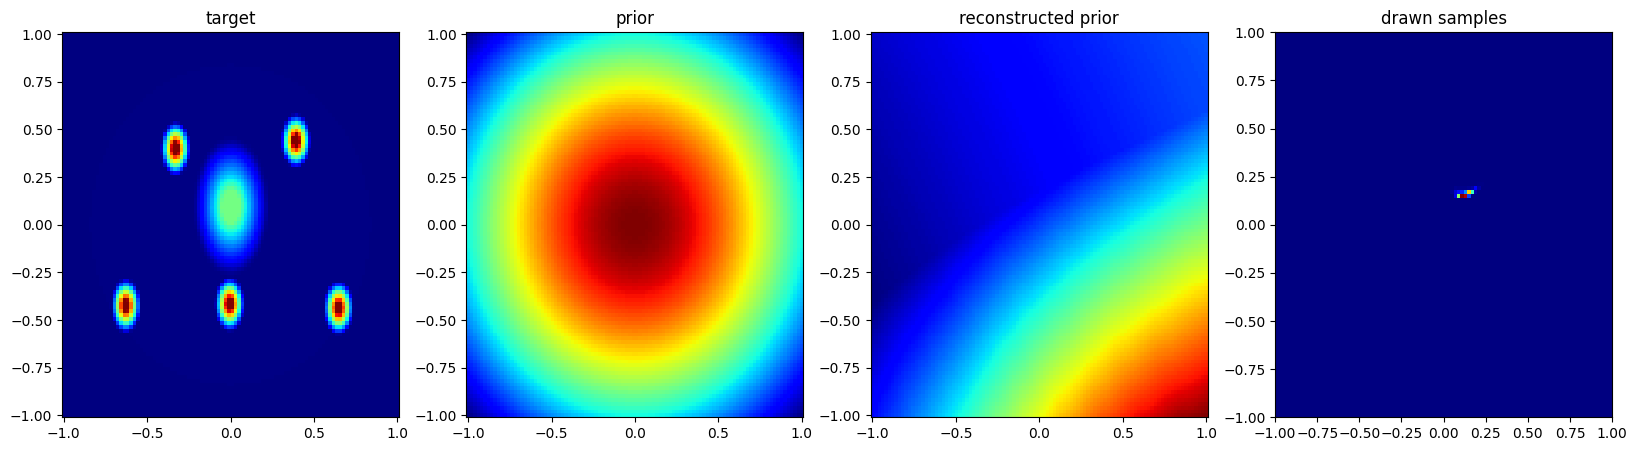

In [ ]:
# img = plt.imread('../assets/test_distributions/complex.png')
# img = plt.imread('../assets/test_distributions/Checkerboard.png')

img = plt.imread('../assets/test_distributions/TestDist2.png')
img = np.sum(img, axis=-1)

# img = plt.imread('../assets/test_distributions/TestTargetDist.png')
target = ImagePrior(img, add_flat_gaussian=True)

num_gaussians = 4

init_means = torch.tensor([[0.5, 0.5], [-0.5, 0.5], [0.5, -0.5], [-0.5, -0.5]])
init_cholesky = torch.tensor([-2, 0.0, -2] * num_gaussians).reshape(num_gaussians, 3)

# target = GMM.GMM(num_gaussians = num_gaussians, init_means=init_means, init_cholesky=init_cholesky)

model = MLP(in_features=2, out_features=2, hidden_layers=[16, 16, 16], activation_function=nn.SiLU(), is_residual=False)

enable_cuda = True
device = torch.device('cuda' if torch.cuda.is_available() and enable_cuda else 'cpu')

q0 = nf.distributions.DiagGaussian((2), trainable=False)
# q0 = nf.distributions.base.Uniform(2, low =-1.0, high = 1.0)
# q0 = Uniform(2, low = 0.0, high = 1.0, device = device)

target.to(device)
model.to(device)
q0.to(device)

vis2dModel(model=model, target=target, prior=q0, device=device)
plt.show()

  0%|          | 0/1000 [00:00<?, ?it/s]

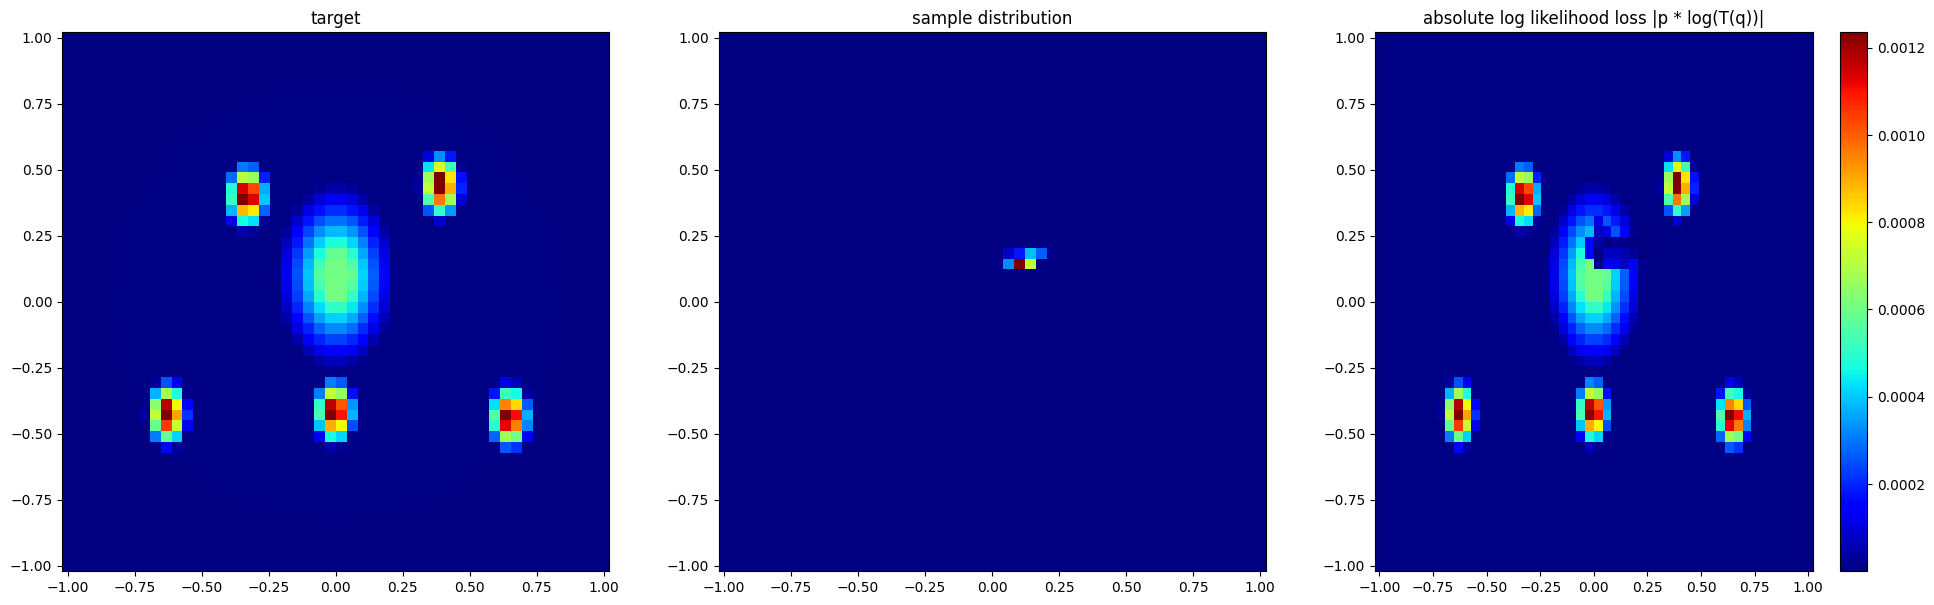

 33%|███▎      | 330/1000 [00:04<00:07, 89.95it/s]

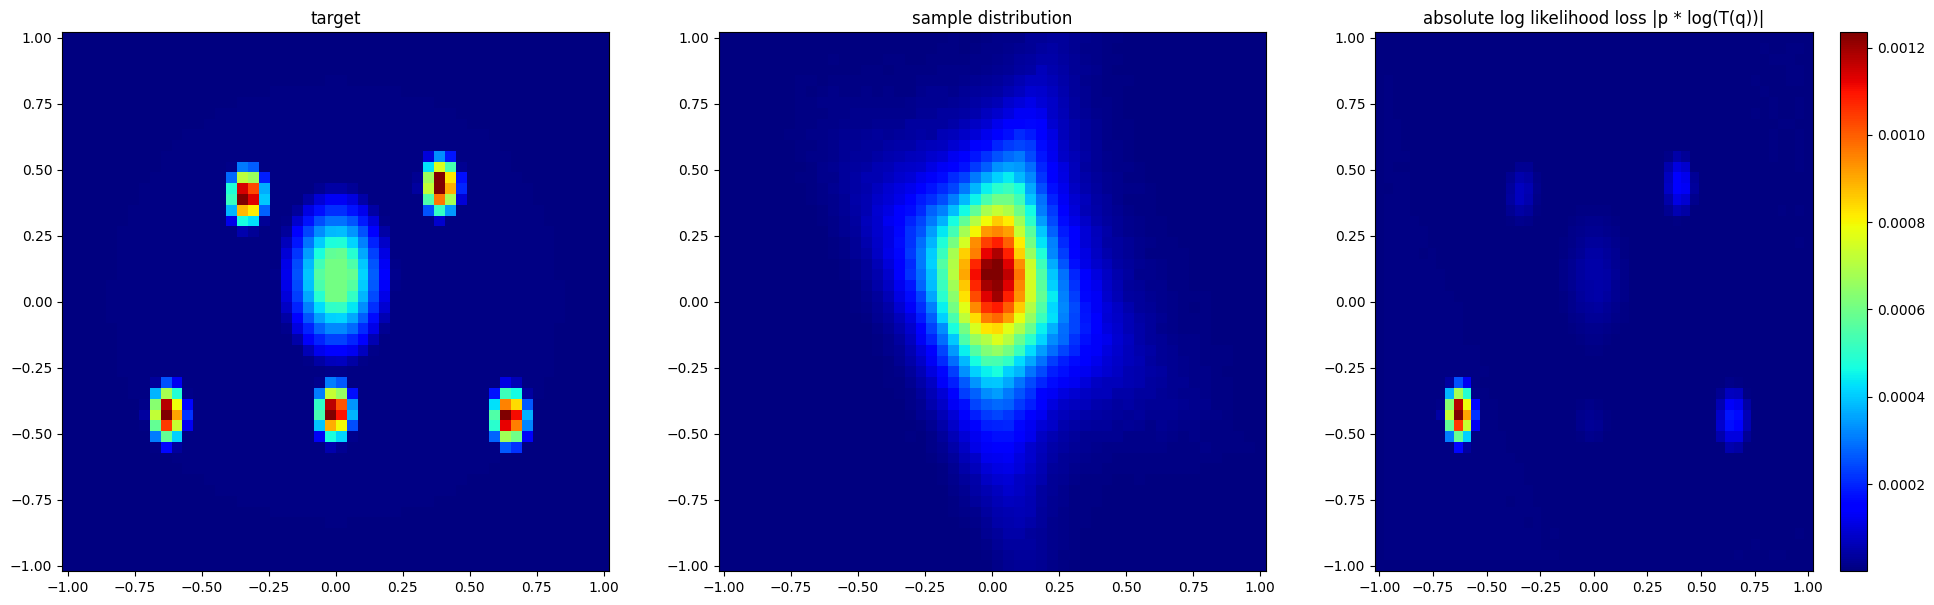

 66%|██████▋   | 663/1000 [00:08<00:03, 87.15it/s]

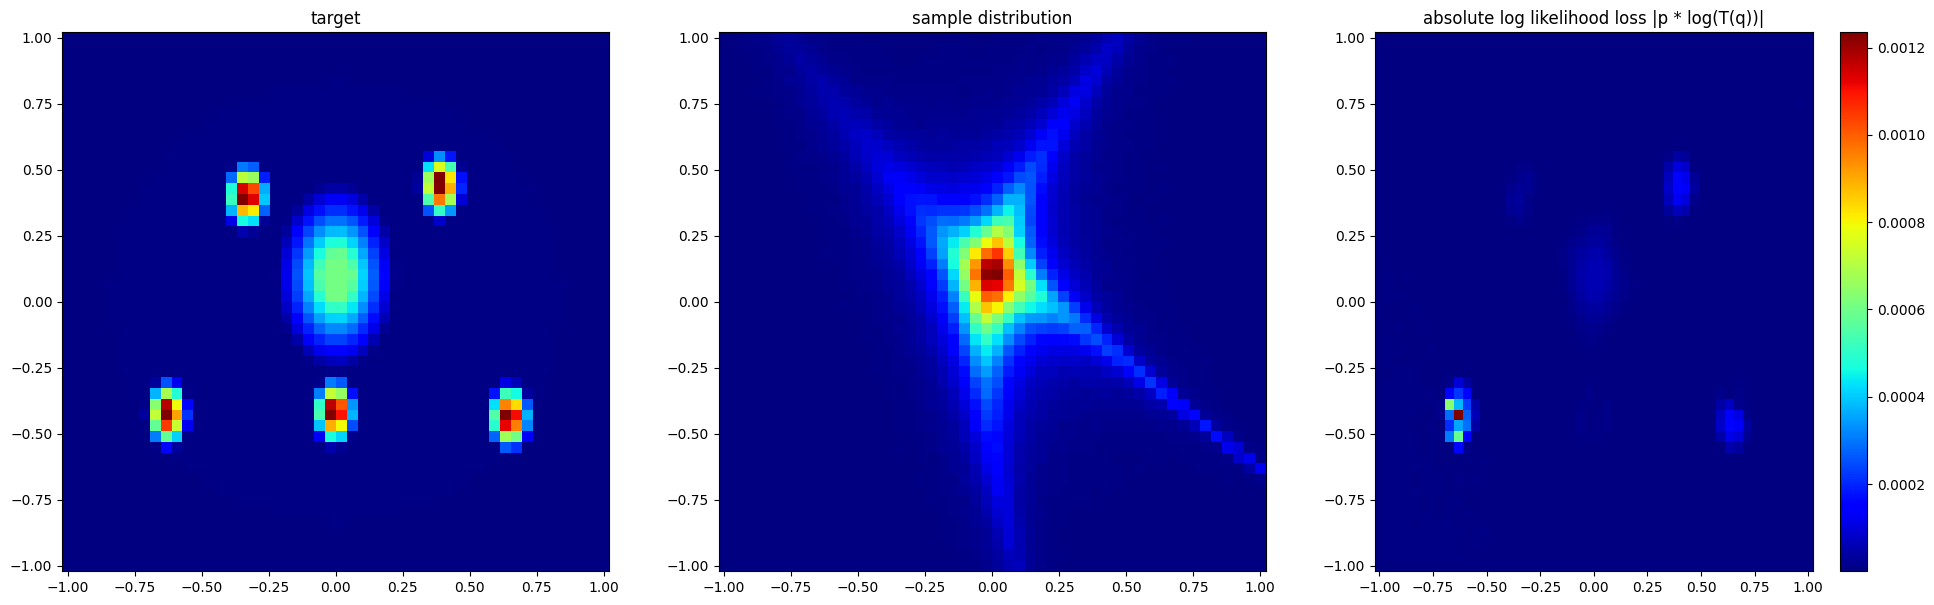

 99%|█████████▉| 991/1000 [00:13<00:00, 86.27it/s]

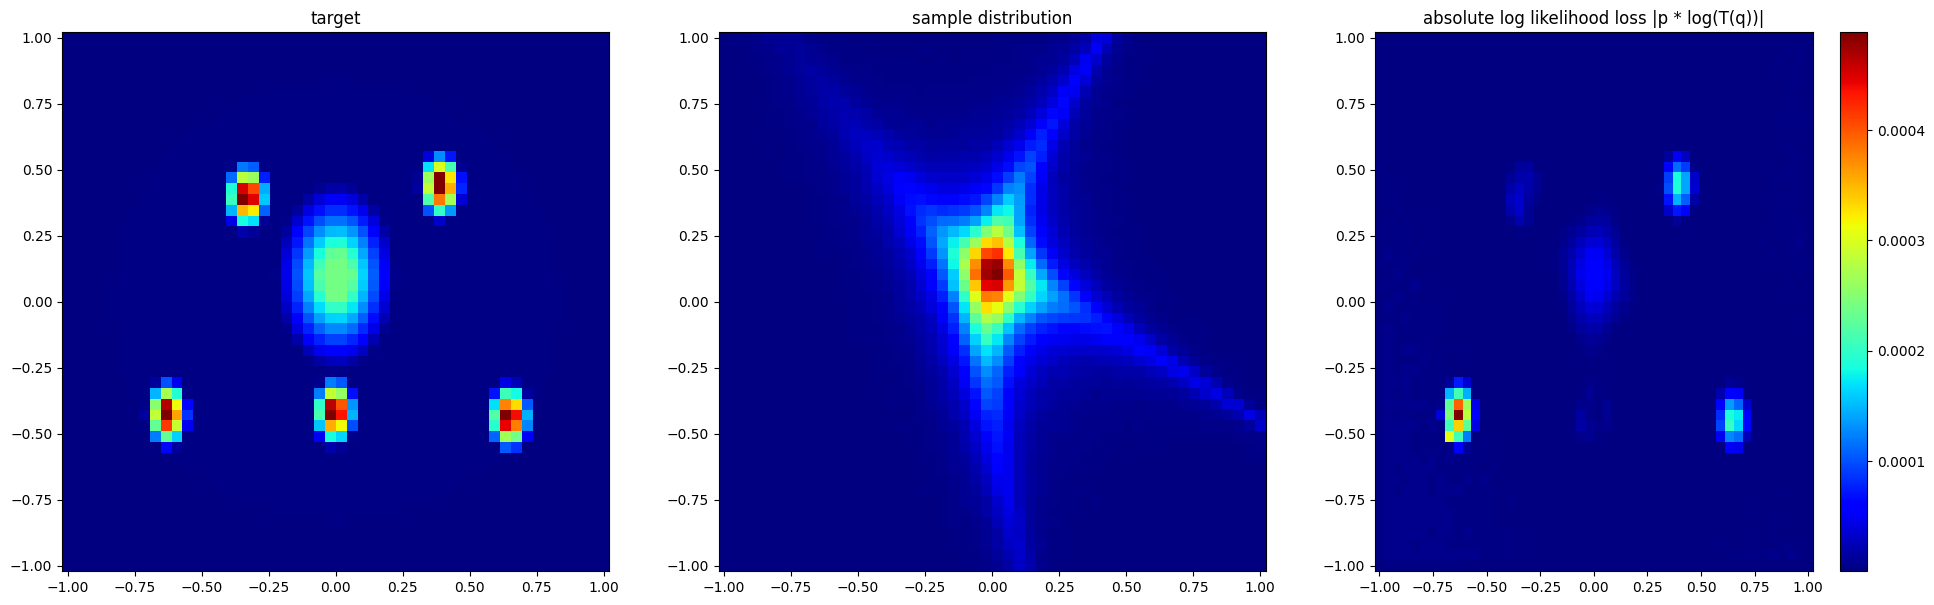

100%|██████████| 1000/1000 [00:13<00:00, 73.73it/s]


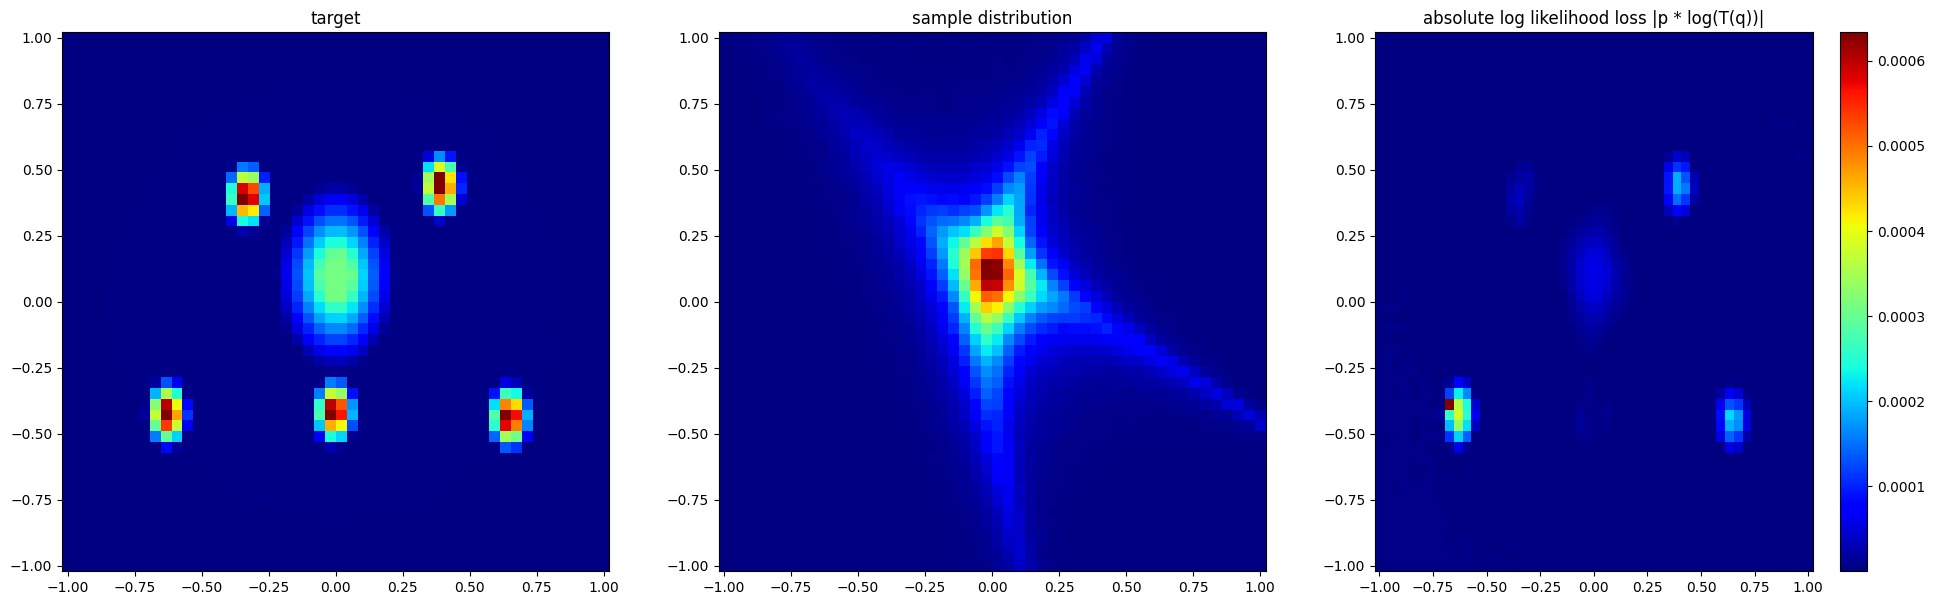

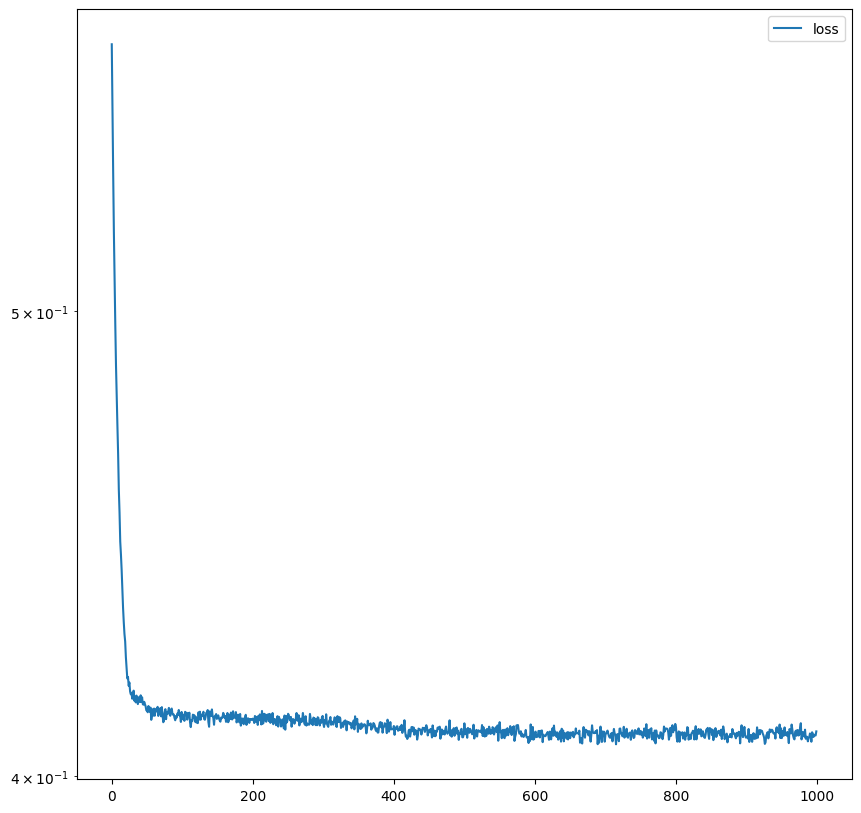

In [ ]:
# Train model
iterations = 1000
num_samples = 2 ** 13

num_training_plots = 3
plot_every = int(iterations / num_training_plots if num_training_plots > 0 else iterations + 1)

grid_size = 100

loss_hist = np.array([])

clip_grad = False
clip_max_norm = 100

add_relu_regu = False

alpha = 1e-3

optimizer = torch.optim.AdamW(model.parameters(), lr=3e-3, weight_decay=1e-4)
jac = torch.func.vmap(torch.func.jacrev(model, chunk_size=1))

base_dist = torch.distributions.Normal(loc = 0, scale = 1)


for it in tqdm.tqdm(range(iterations)):
    optimizer.zero_grad()

    # z = q0.sample(num_samples)

    ### Can sample uniformly when accounting for that in loss
    z = torch.rand((num_samples, 2), device = device) * 2 - 1

    log_probs_q = q0.log_prob(z)
    probs_q = torch.exp(log_probs_q)
    
    jacobians = jac(z)
    abs_dets = torch.det(jacobians).clamp(min = 1e-4)

    # dets = computeJacDets(model, z)
    # abs_dets = dets.clamp(min = 1e-4)

    y = model(z)
    probs_f = target.log_prob(y).exp()

    Is = I(z)
    probs_I = target.log_prob(Is).exp()

    dets_I = I_abs_det(z)

    f_loss = (1 - alpha) * probs_f * abs_dets
    I_loss =      alpha  * probs_I * dets_I

    # losses = -torch.log(f_loss + I_loss)

    ### Use this loss when sampling uniformly
    losses = -torch.log(f_loss + I_loss) * probs_q / 4
    loss = torch.mean(losses[~(torch.isnan(losses) | torch.isinf(losses))])
    
    if add_relu_regu:
        loss += relu_reg(y)

    if ~(torch.isnan(loss) | torch.isinf(loss)):
        loss.backward()

        if clip_grad:
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=clip_max_norm)

        optimizer.step()
        
        loss_hist = np.append(loss_hist, loss.to('cpu').data.numpy())

    if (it != 0 or plot_every < iterations) and it % plot_every == 0: 
        # vis2dModel(model=model, target=target, prior=q0, device=device)
        vis2dModel_loss(model, target, q0, device, num_samples=1000000)

# vis2dModel(model=model, target=target, prior=q0, device=device)
vis2dModel_loss(model, target, q0, device, num_samples=1000000)


plt.figure(figsize=(10, 10))
plt.semilogy(loss_hist, label='loss')
plt.legend()
plt.show()

In [ ]:
from torch.autograd import forward_ad

import time

def current_milli_time():
    return round(time.time() * 1000)

B, D = 2**10, 2
z = torch.rand((B, D), device=device) * 2 - 1

start = current_milli_time() 

dets_old = computeJacDets(model, z)

print(f"time for old calc: {current_milli_time() - start} ms")
# print(f"dets old: {dets_old}")


def compute_dual(tangent):
    tangents = tangent.unsqueeze(0).expand((B, D))

    # Make z dual: (B, D)
    z_dual = forward_ad.make_dual(z, tangents)  # batch of dual tensors
    
    # Forward propagate
    y_dual = model(z_dual)                  # (B, out_dim)

    # Extract tangents
    return forward_ad.unpack_dual(y_dual)      # Js: (B, out_dim, D)


start = current_milli_time() 
with forward_ad.dual_level():
    # Create tangent vectors: one per input dim
    eye = torch.eye(D, device=device)           # (D, D)
    tangent1 = torch.tensor([1, 0], dtype=torch.float32, device=device)
    tangent2 = torch.tensor([0, 1], dtype=torch.float32, device=device)


    # Extract tangents
    y1, cols1 = compute_dual(tangent=tangent1)    # Js: (B, out_dim, D)
    _, cols2 = compute_dual(tangent=tangent2)    # Js: (B, out_dim, D)
    
    J = torch.stack((cols1, cols2), dim = 1)
    dets_new = torch.det(J)

    dets_diff = dets_old - dets_new
    abs_diff = dets_diff.abs().sum()

    print(f"time for new calc: {current_milli_time() - start} ms")

    # print(f"dets new: {dets_new}")
    print(f"abs diff: {abs_diff}")



time for old calc: 2 ms
time for new calc: 1905 ms
abs diff: 1.2227974366396666e-07


In [ ]:
device = 'cuda'

D = 2
B = 4
z = torch.rand((B, D), device = device) * 2 - 1

dets = computeJacDets(model, z, loop_batch=False)
print(dets)

p:\Programs\miniconda3\envs\master-pytorch\Lib\site-packages\torch\autograd\graph.py:829: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\cuda\CublasHandlePool.cpp:179.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


tensor([-3.4874e-05,  2.2099e-05, -4.0848e-05,  1.3394e-05], device='cuda:0',
       grad_fn=<LinalgDetBackward0>)


# Summary of jacrev issues

- https://github.com/pytorch/pytorch/issues/91810#issue-1522837470
- GradTrackingTensor is the datatype of tensor which is passed when a function is called by vmap(jacrev)
- GradTrackingTensor seemingly does not expose it's storage, leading with incompatibility with the hash encoding, which needs values
- the replacement, torch.autograd.functional.jacobian does not support batched per-sample jacobians. 
- Seemingly, this is a bug in pytorch's cuda implementation. This seems to work on cpu
- possible workaround ??
    - https://docs.pytorch.org/docs/stable/notes/extending.func.html#defining-the-vmap-staticmethod

# With encoding

using device: cuda


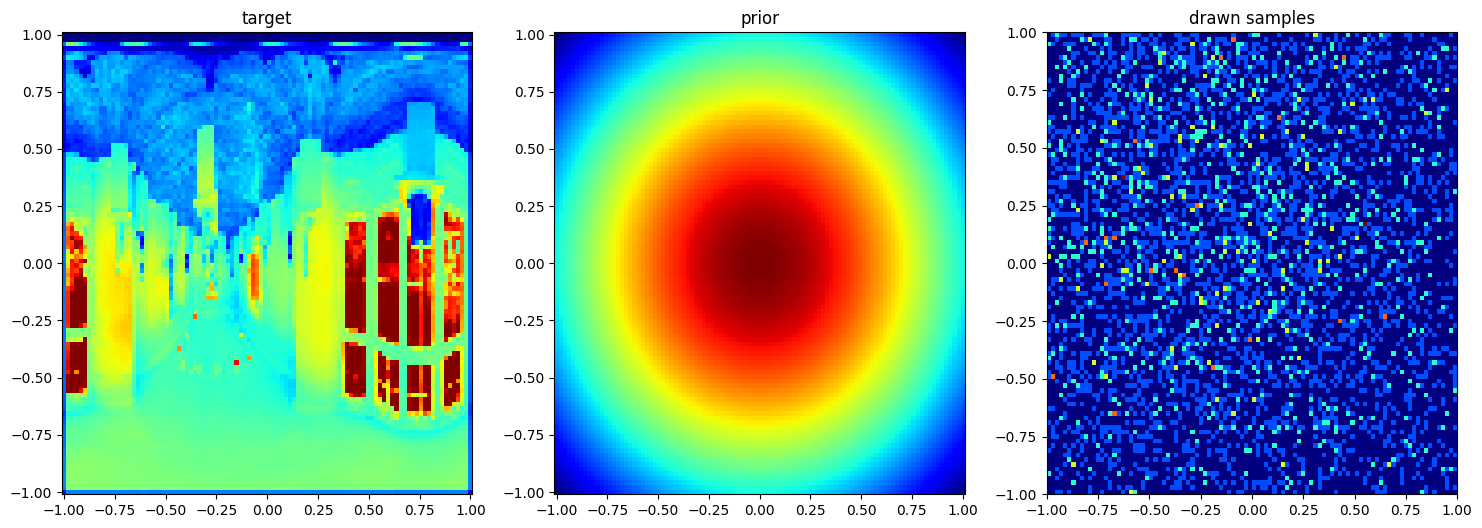

In [40]:
# img = plt.imread('../assets/test_distributions/complex.png')
# img = plt.imread('../assets/test_distributions/Checkerboard.png')
img = plt.imread('../assets/test_distributions/museum.jpg').sum(axis=-1)

from torch import unsqueeze


# img = plt.imread('../assets/test_distributions/TestDist2.png')
# img = np.sum(img, axis=-1)

# img = plt.imread('../assets/test_distributions/TestTargetDist.png')
target = ImagePrior(img, add_flat_gaussian=False)

enable_cuda = True
device = torch.device('cuda' if torch.cuda.is_available() and enable_cuda else 'cpu')

conf = MultiresEncodingConfig()

conf.nlevels = 8
conf.minres = (16, 16)
conf.maxres = (512, 512)

encoding = MultiresEncoding(**vars(conf), dtype=torch.float32, device = device)


model = MLP(in_features=encoding.encoding_size, 
            out_features=2, 
            hidden_layers=[16, 16, 16], 
            activation_function=nn.SiLU(), 
            is_residual=False)

def eval_model(x: torch.Tensor): 
    unsqueezed = False
    if len(x.shape) == 1:
        unsqueezed = True
        x = x.unsqueeze(0)
    enc = encoding(x)
    res = x + model(enc)
    if unsqueezed:
        return res.squeeze(0)
    return res

q0 = nf.distributions.DiagGaussian((2), trainable=False)
# q0 = nf.distributions.base.Uniform(2, low =-1.0, high = 1.0)
# q0 = Uniform(2, low = 0.0, high = 1.0, device = device)

print(f"using device: {device}")

target.to(device)
model.to(device)
q0.to(device)

vis2dModel(model=eval_model, target=target, prior=q0, device=device)
plt.show()

  0%|          | 0/500 [00:00<?, ?it/s]

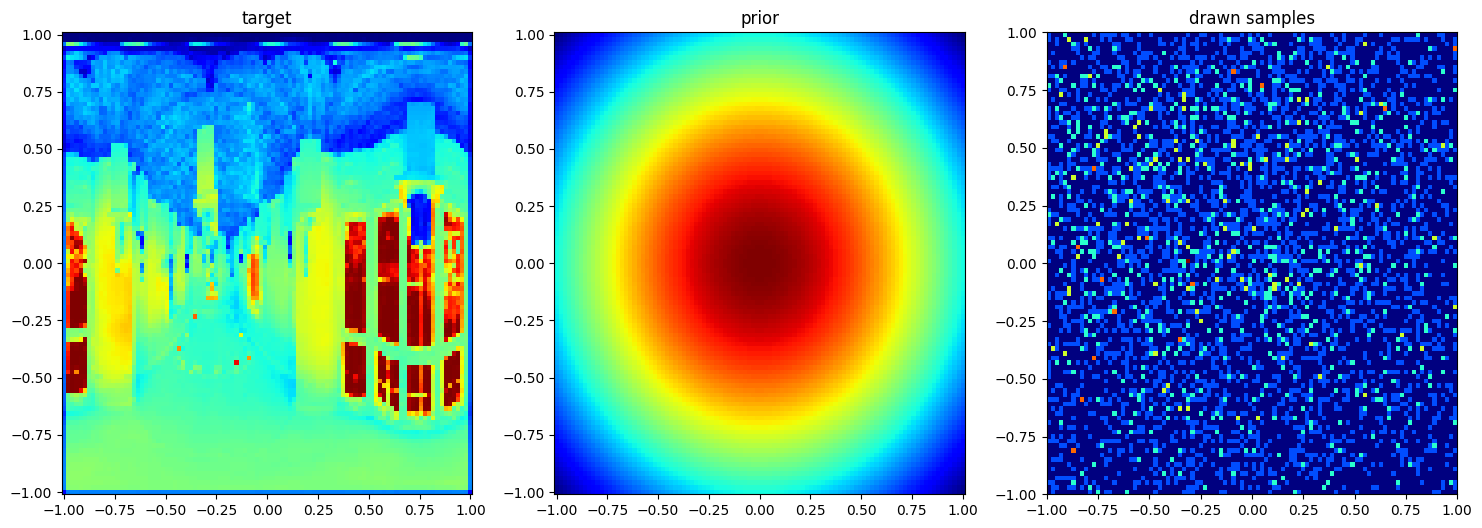

 50%|████▉     | 249/500 [00:17<00:16, 14.83it/s]

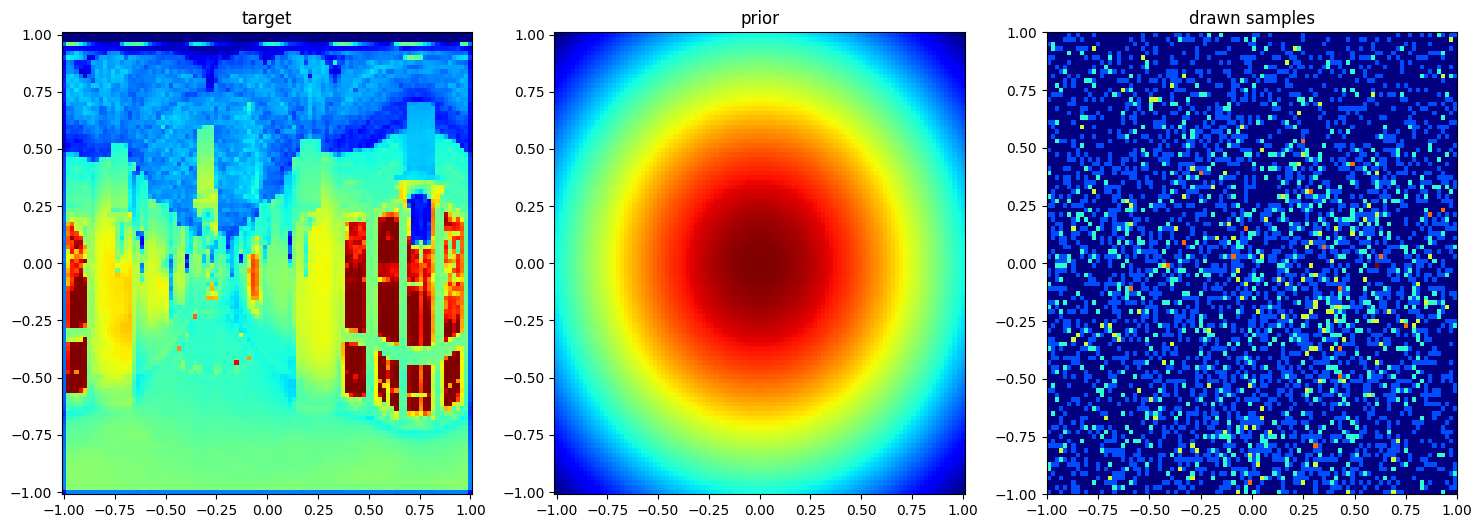

100%|██████████| 500/500 [00:34<00:00, 14.46it/s]


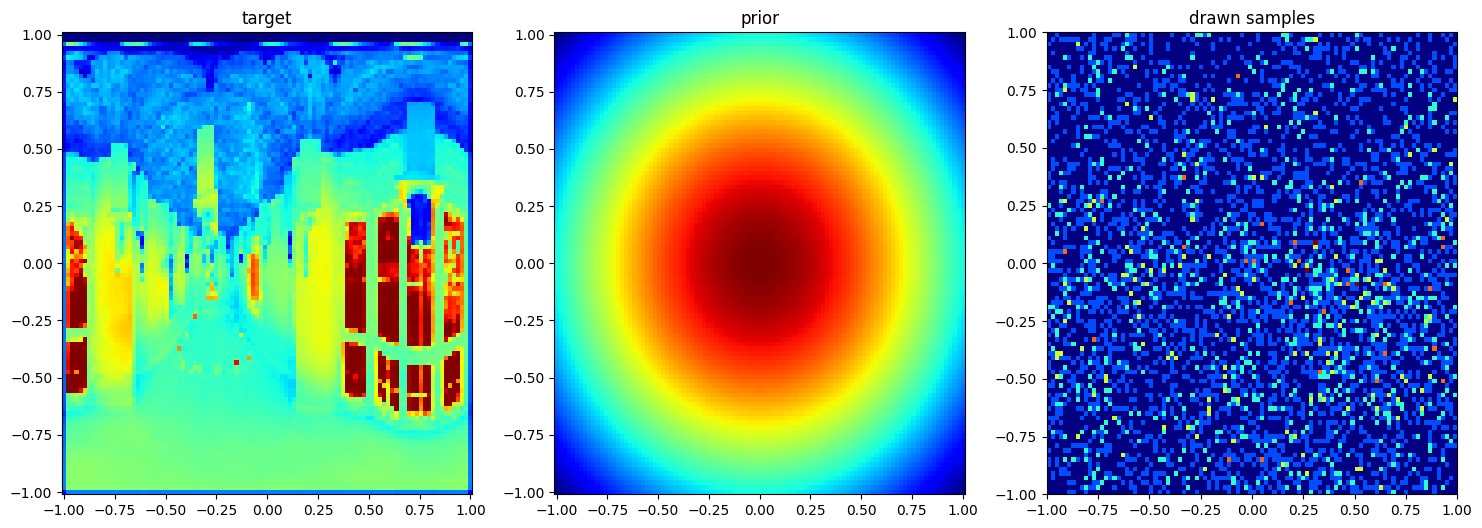

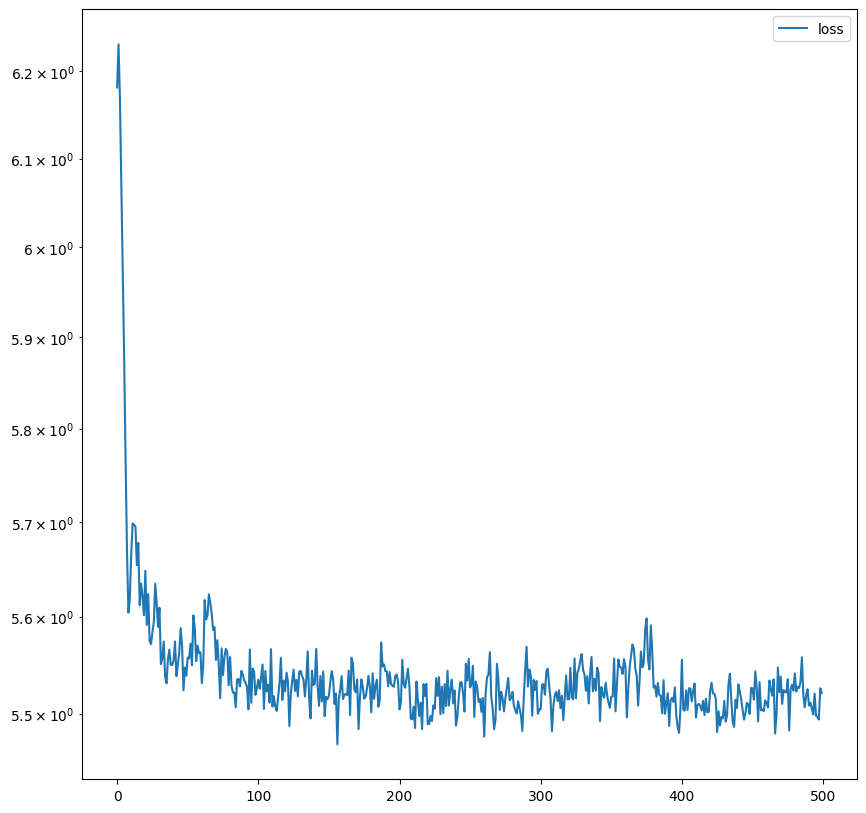

In [41]:
# Train model
iterations = 500
num_samples = 2 ** 12

num_training_plots = 2
plot_every = int(iterations / num_training_plots if num_training_plots > 0 else iterations + 1)

grid_size = 100

loss_hist = np.array([])

model_norms = np.array([])
enc_norms = np.array([])

jac = torch.func.vmap(torch.func.jacrev(eval_model, chunk_size=1))

clip_grad = True
track_grad = False
clip_max_norm = 5

add_relu_regu = False

alpha = 1e-3

pm = model.parameters()
pe = encoding.parameters()

p = list(pm) + list(pe)
optimizer = torch.optim.AdamW(p, lr=1e-2, weight_decay=4e-4)

base_dist = torch.distributions.Normal(loc = 0, scale = 1)


for it in tqdm.tqdm(range(iterations)):
    optimizer.zero_grad()

    # z = q0.sample(num_samples)

    ### Can sample uniformly when accounting for that in loss
    z = torch.rand((num_samples, 2), device = device) * 2 - 1

    log_probs_q = q0.log_prob(z)
    probs_q = torch.exp(log_probs_q)
    
    jacobians = jac(z)
    abs_dets = torch.det(jacobians).clamp(min = 1e-4)

    # dets = computeJacDets(eval_model, z)
    # abs_dets = dets.clamp(min = 1e-4)


    y = eval_model(z)
    probs_f = target.log_prob(y).exp()

    Is = I(z)
    probs_I = target.log_prob(Is).exp()

    dets_I = I_abs_det(z)

    f_loss = (1 - alpha) * probs_f * abs_dets
    I_loss =      alpha  * probs_I * dets_I

    # losses = -torch.log(f_loss + I_loss)

    ### Use this loss when sampling uniformly
    losses = -torch.log(f_loss + I_loss) * probs_q * 4
    losses_clean = losses[~(torch.isnan(losses) | torch.isinf(losses))]
    loss = torch.mean(losses_clean)
    
    if add_relu_regu:
        loss += relu_reg(y)

    if ~(torch.isnan(loss) | torch.isinf(loss)):
        loss.backward()

        if clip_grad:
            ### Only network
            # torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=clip_max_norm)

            ### Network and Encoding clipping
            torch.nn.utils.clip_grad_norm_(p, max_norm=clip_max_norm)

            if track_grad:
                norm = 0
                for ps in p:
                    param_norm = ps.grad.detach().data.norm(2)
                    norm += param_norm.item() ** 2
                norm = norm ** 0.5
                norms = np.append(norms, norm)

        optimizer.step()
        
        loss_hist = np.append(loss_hist, loss.to('cpu').data.numpy())

    if (it != 0 or plot_every < iterations) and it % plot_every == 0: 
        vis2dModel(model=eval_model, target=target, prior=q0, device=device)
        # vis2dModel_loss(eval_model, target, q0, device, num_samples=1000000)


vis2dModel(model=eval_model, target=target, prior=q0, device=device)
# vis2dModel_loss(eval_model, target, q0, device, num_samples=1000000)


plt.figure(figsize=(10, 10))
plt.semilogy(loss_hist, label='loss')
plt.legend()
plt.show()

if track_grad:
    plt.figure(figsize=(10, 10))
    plt.plot(model_norms, label='Model norms')
    plt.plot(enc_norms, label='Encoding norms')
    plt.legend()
    plt.show()

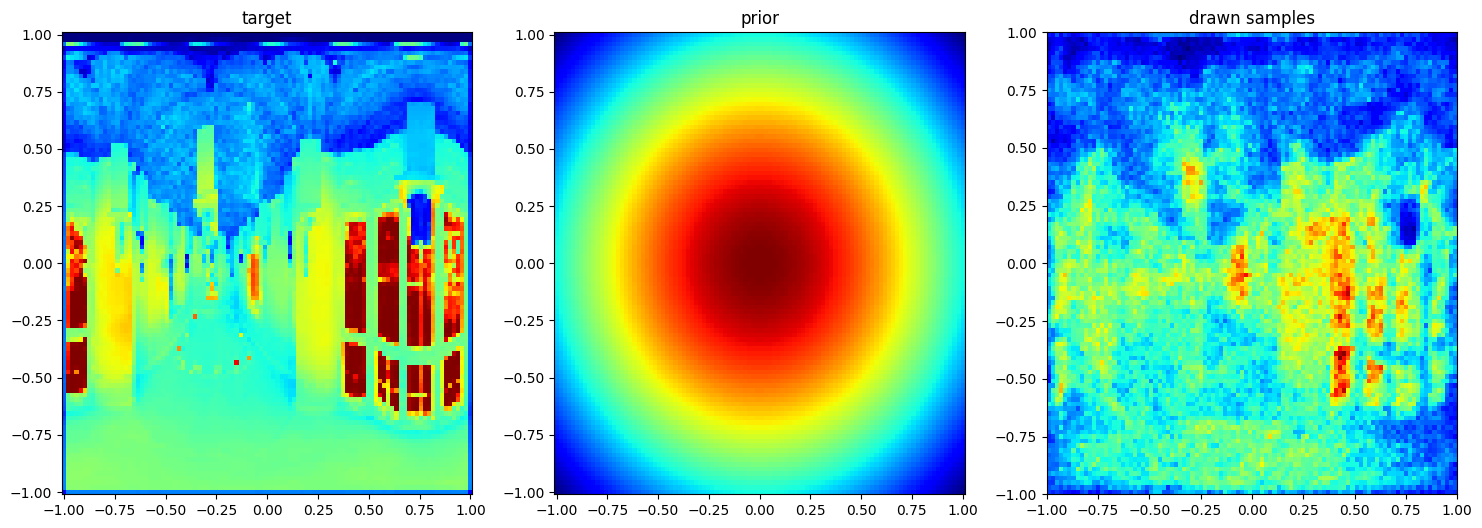

In [ ]:
vis2dModel(model=eval_model, target=target, prior=q0, device=device, num_samples=5000000)
# vis2dModel_loss(eval_model, target, q0, device, num_samples=1000000)


# Test: Using Abstract Model Interface

In [10]:
import models
import priors
import targets
importlib.reload(models)
importlib.reload(priors)
importlib.reload(targets)
import models
import priors
import targets

# TODO: Add way to specifiy feature count
def get_default_encoding(device):
    conf = MultiresEncodingConfig()

    conf.nlevels = 8
    conf.minres = (16, 16)
    conf.maxres = (512, 512)

    return MultiresEncoding(**vars(conf), dtype=torch.float32, device = device)

def get_default_prior(means, stds):
    return priors.DiagGaussianPrior(means, stds)

def get_default_target(domain, normalize = False):
    img = plt.imread('../assets/test_distributions/museum.jpg').sum(axis=-1)
    return targets.ImageTarget(img, domain = domain, add_flat_gaussian=False, normalize=normalize)


d:\Studium\Masters\Masters\scripts\..\src\priors.py:15: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.register_buffer("means", torch.tensor(means, dtype=dtype))
d:\Studium\Masters\Masters\scripts\..\src\priors.py:16: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.register_buffer("stds", torch.tensor(stds, dtype=dtype))
p:\Programs\miniconda3\envs\master-pytorch\Lib\site-packages\torch\functional.py:554: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4324.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[at

using device: cuda


C:\Users\janlu\AppData\Local\Temp\ipykernel_11760\2712940554.py:22: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


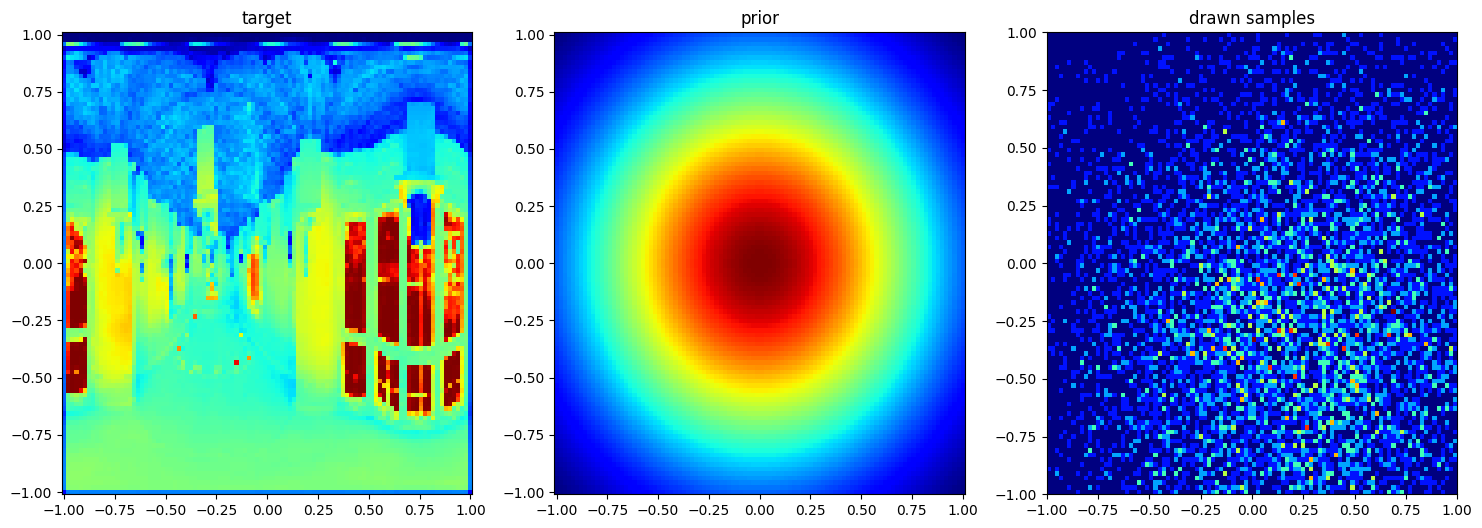

In [11]:
enable_cuda = True
device = torch.device('cuda' if torch.cuda.is_available() and enable_cuda else 'cpu')

# domain = torch.as_tensor([[0, torch.pi * 2], [0, torch.pi]])
domain = torch.as_tensor([[-1, 1], [-1, 1]])
means = (domain[:, 1] + domain[:, 0]) / 2
stds = (domain[:, 1] - domain[:, 0]) / (torch.pi) #) * 2)

prior = get_default_prior(means, stds)
encoding = get_default_encoding(device)
hidden_layers = [16, 16, 16]

model: models.AbstractModel = models.ReparameterizationModel(2, prior, encoding, hidden_layers, domain=domain)
target = get_default_target(domain = domain)


model.to(device)
target.to(device)
print(f"using device: {device}")

fig = model.visualize(target)
fig.show()

  0%|          | 0/1000 [00:00<?, ?it/s]

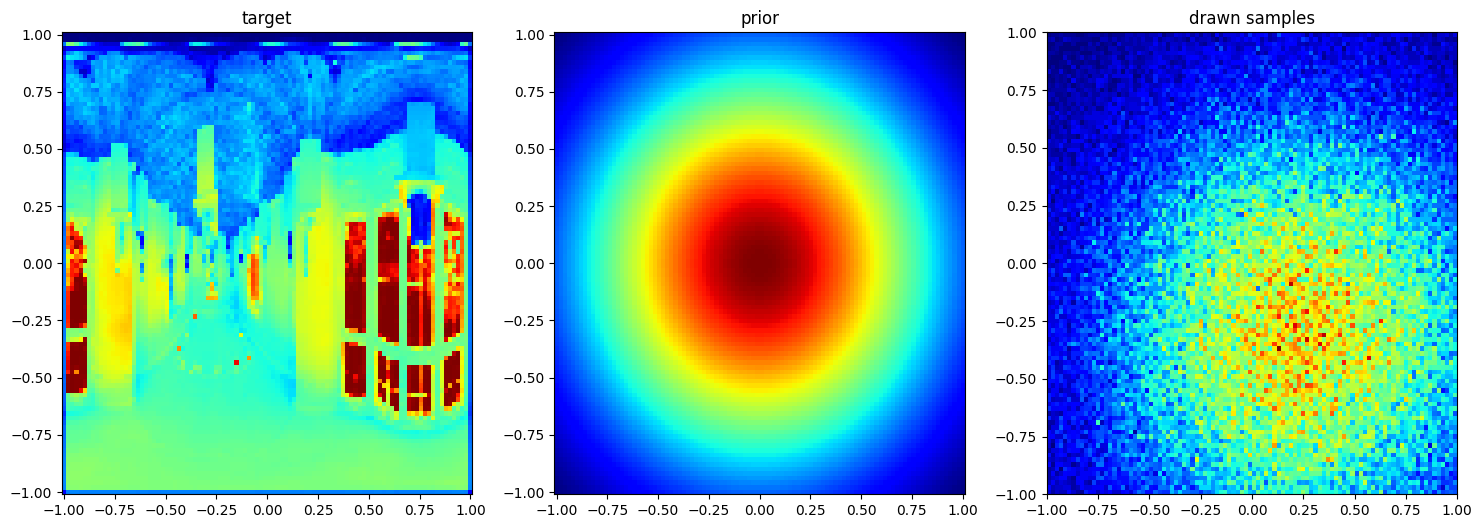

 10%|▉         | 99/1000 [00:07<01:04, 14.00it/s]

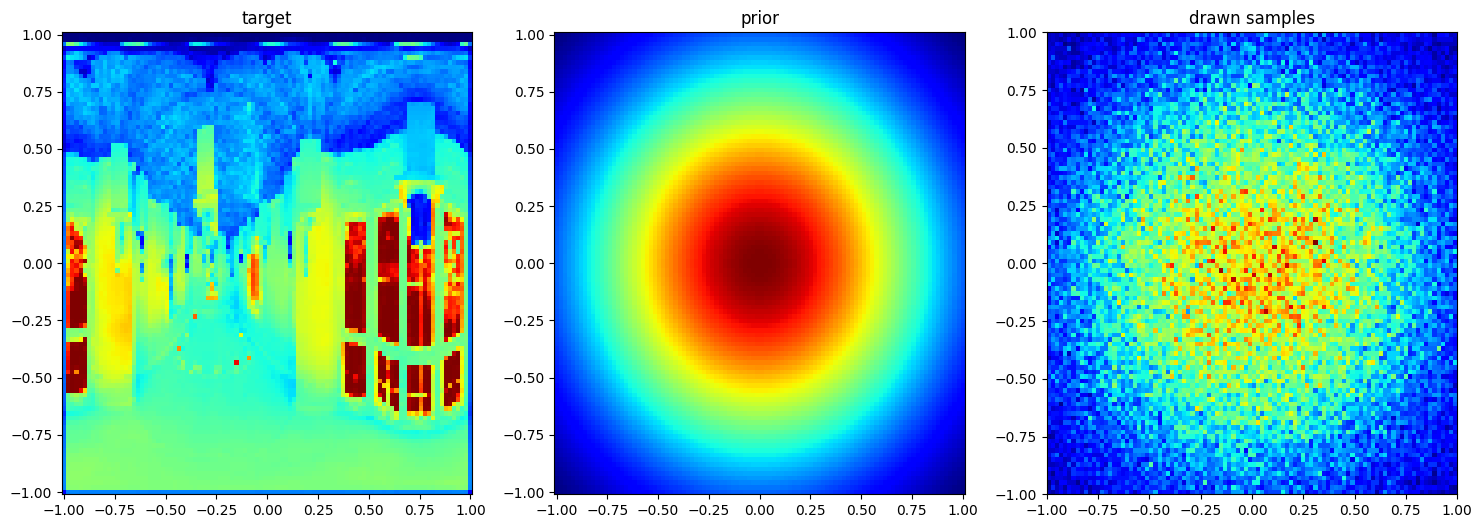

 20%|█▉        | 199/1000 [00:15<00:56, 14.15it/s]

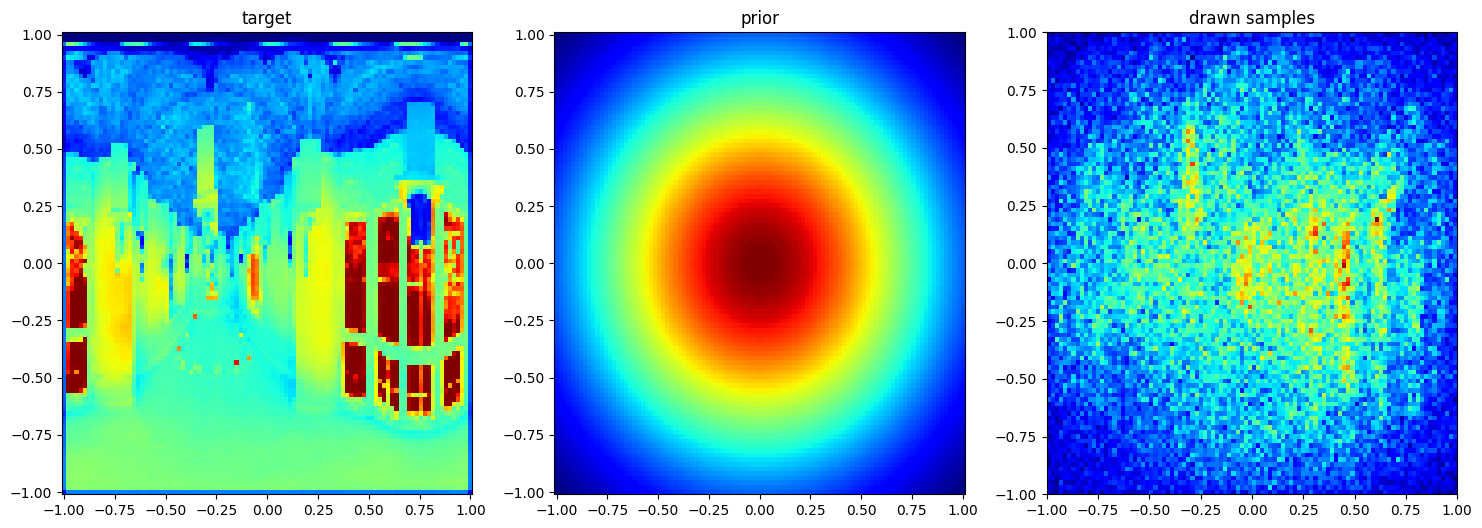

 30%|██▉       | 299/1000 [00:22<00:49, 14.14it/s]

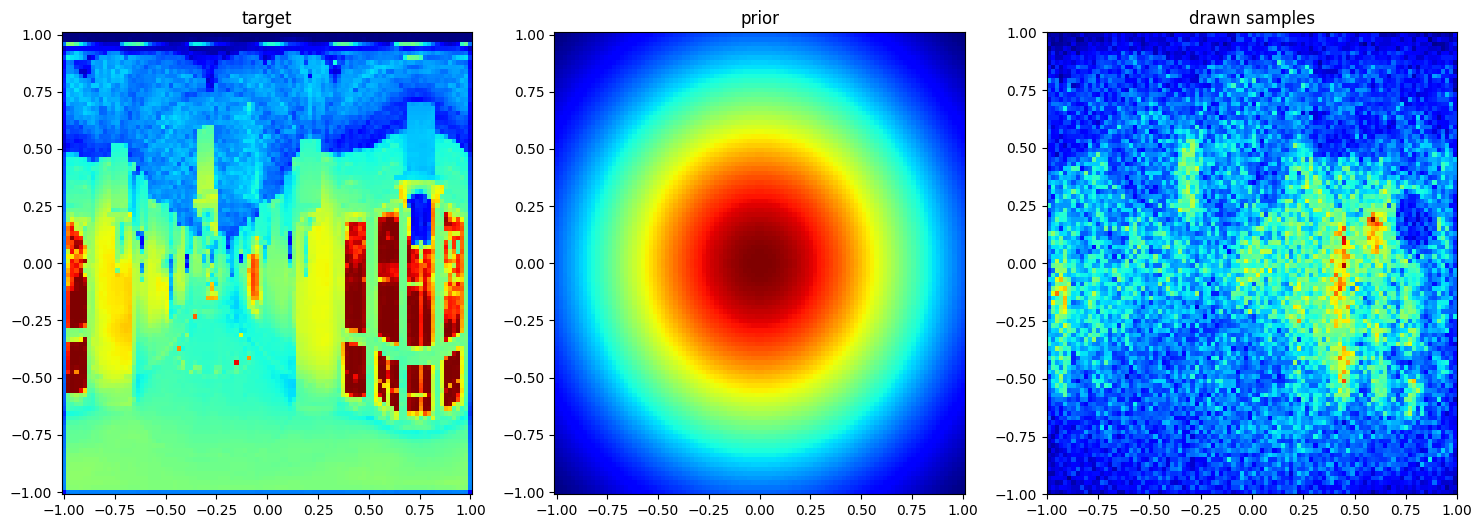

 40%|███▉      | 399/1000 [00:30<00:47, 12.57it/s]

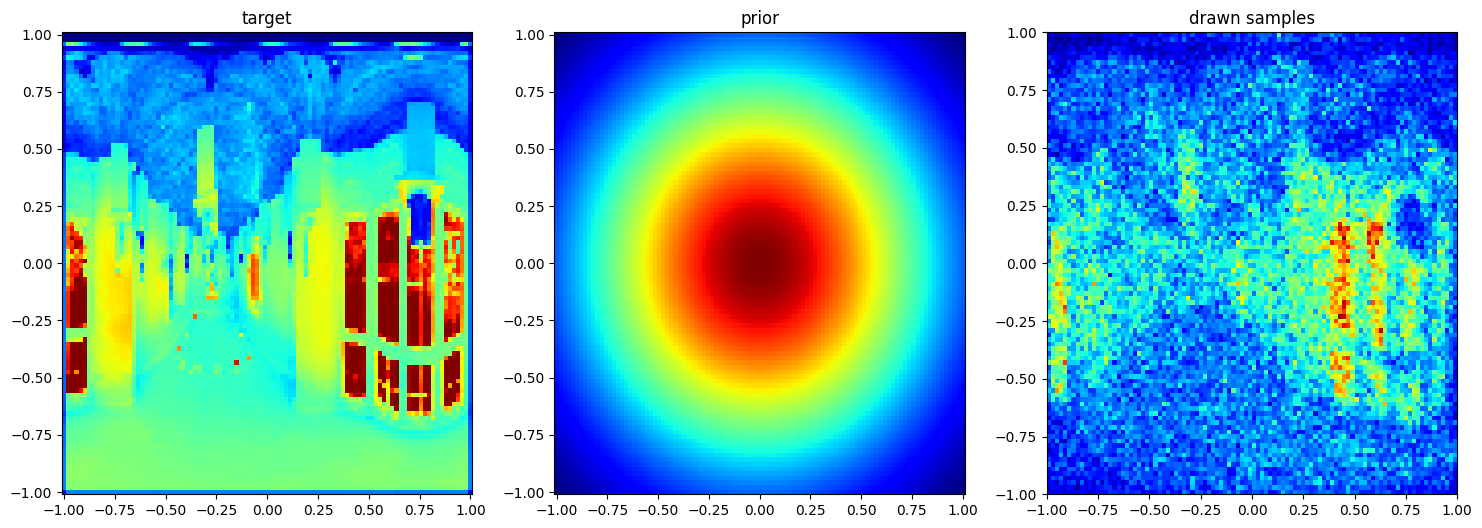

 50%|████▉     | 499/1000 [00:37<00:34, 14.51it/s]

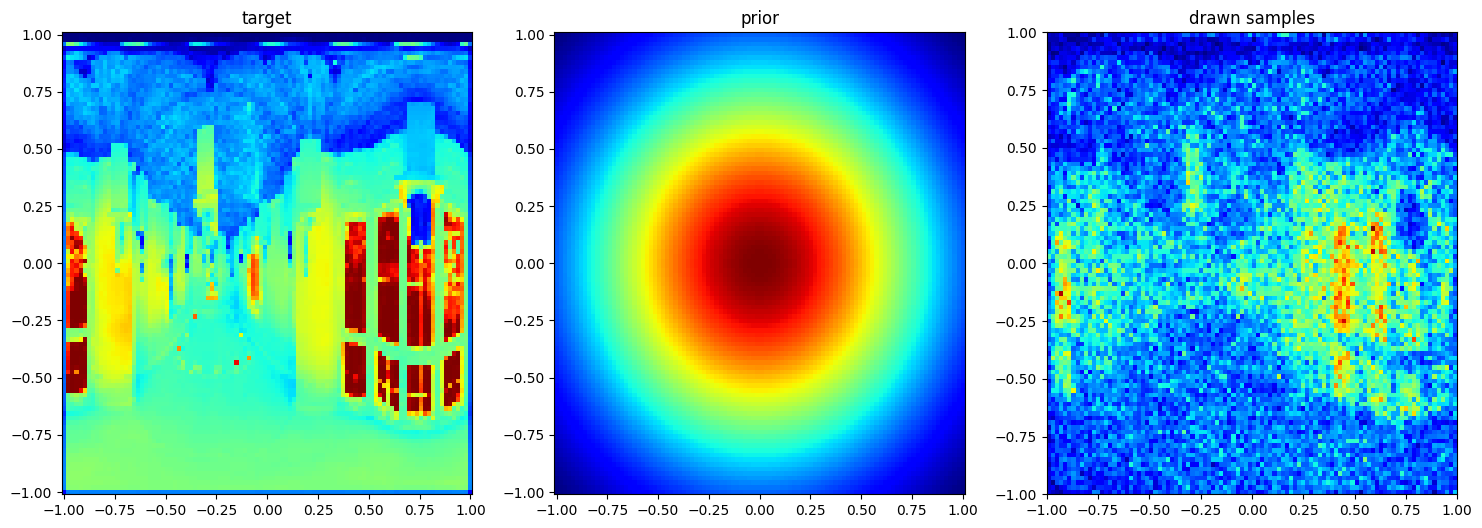

 60%|█████▉    | 599/1000 [00:45<00:27, 14.54it/s]

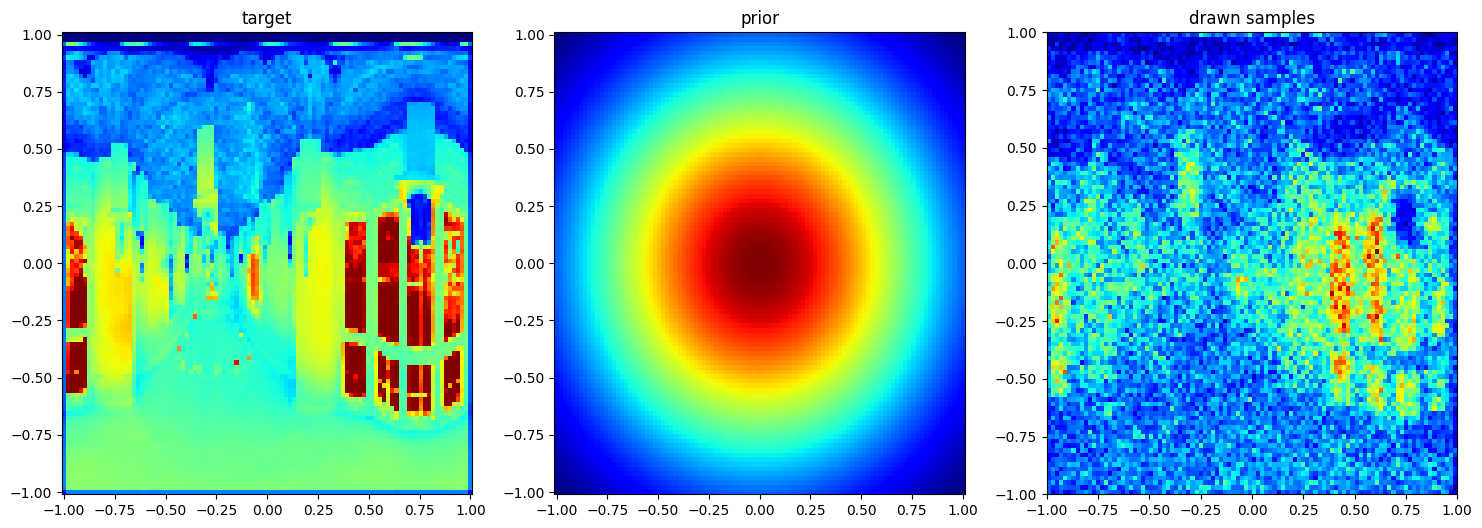

 70%|██████▉   | 699/1000 [00:52<00:21, 13.90it/s]

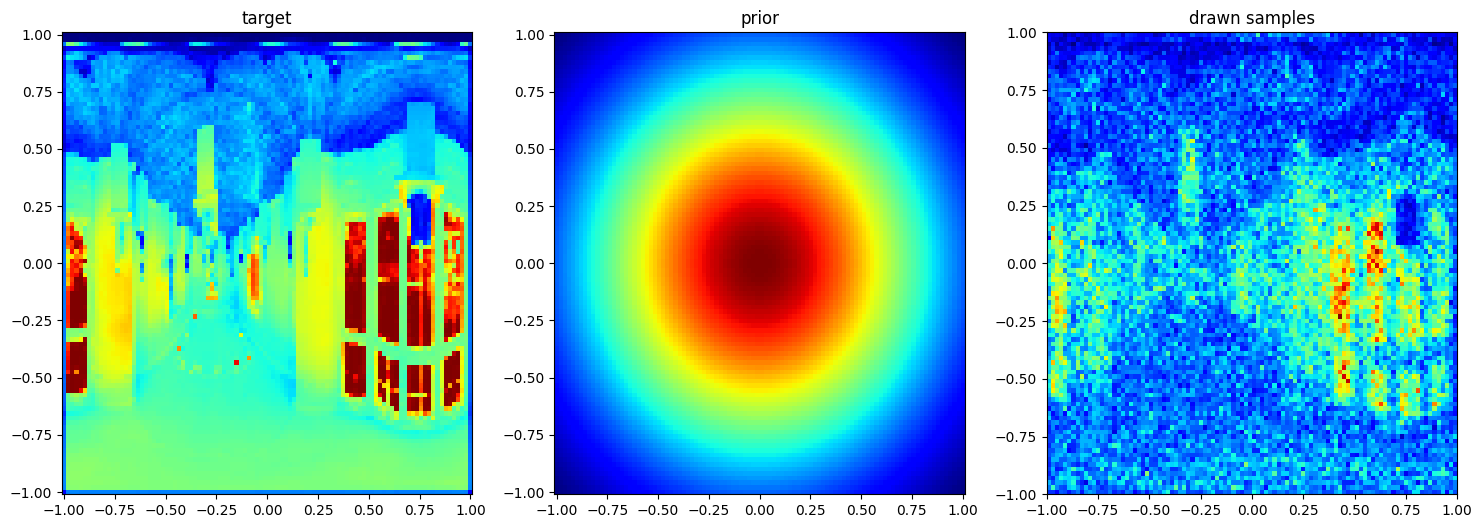

 80%|███████▉  | 799/1000 [00:59<00:13, 14.42it/s]

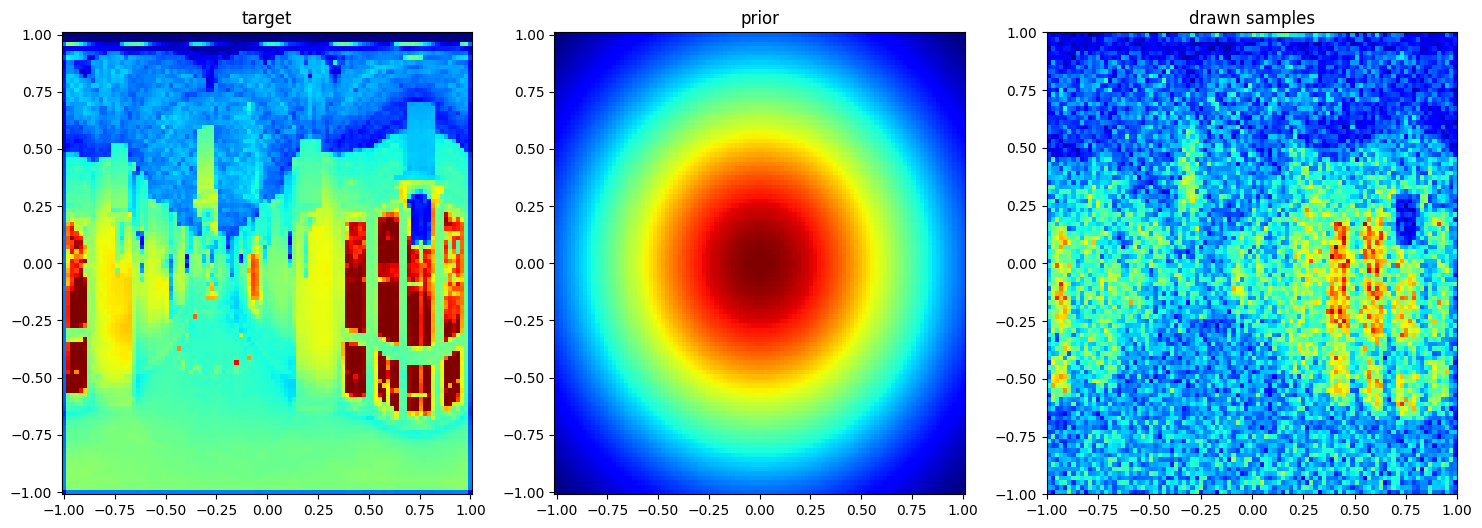

 90%|████████▉ | 899/1000 [01:07<00:07, 13.39it/s]

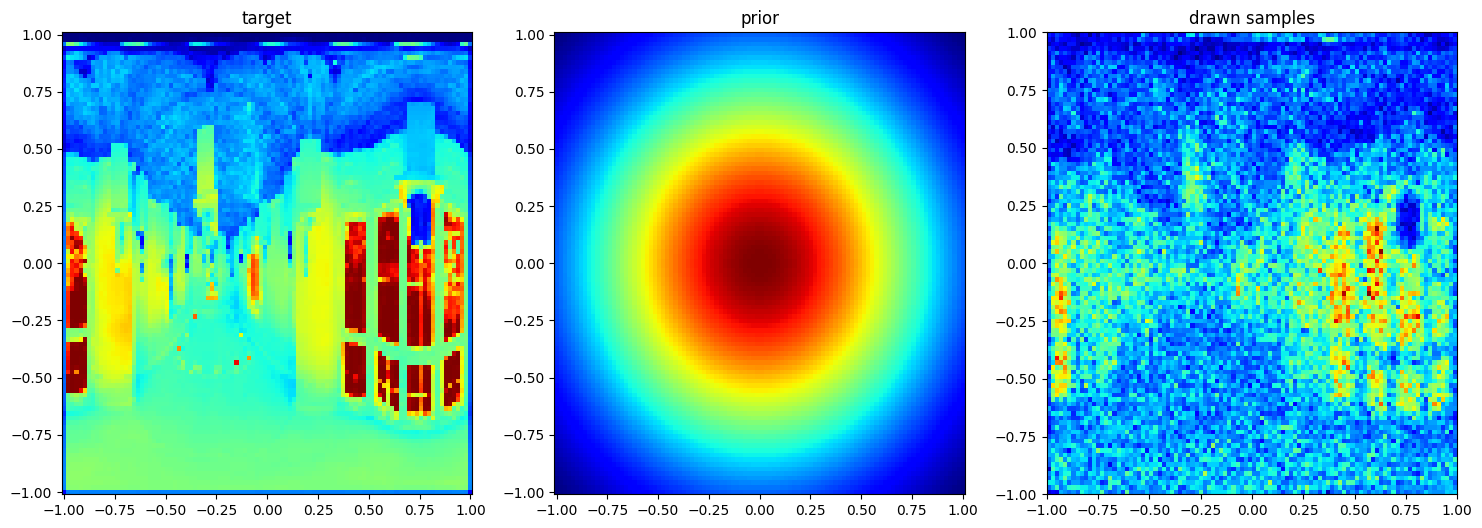

100%|██████████| 1000/1000 [01:15<00:00, 13.26it/s]


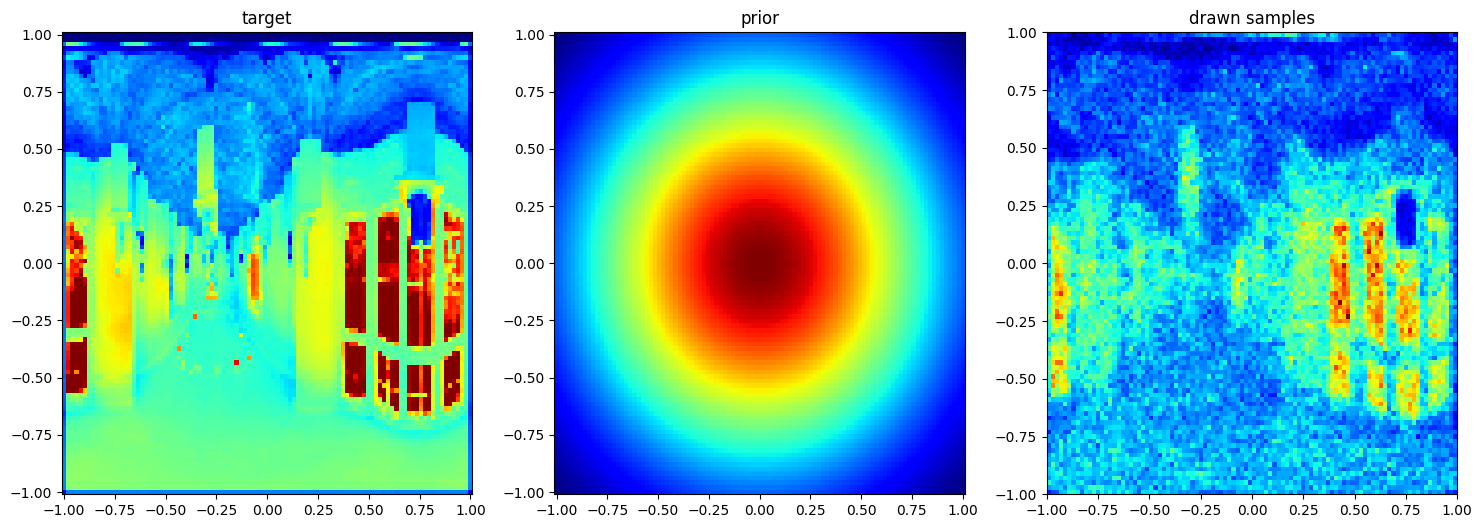

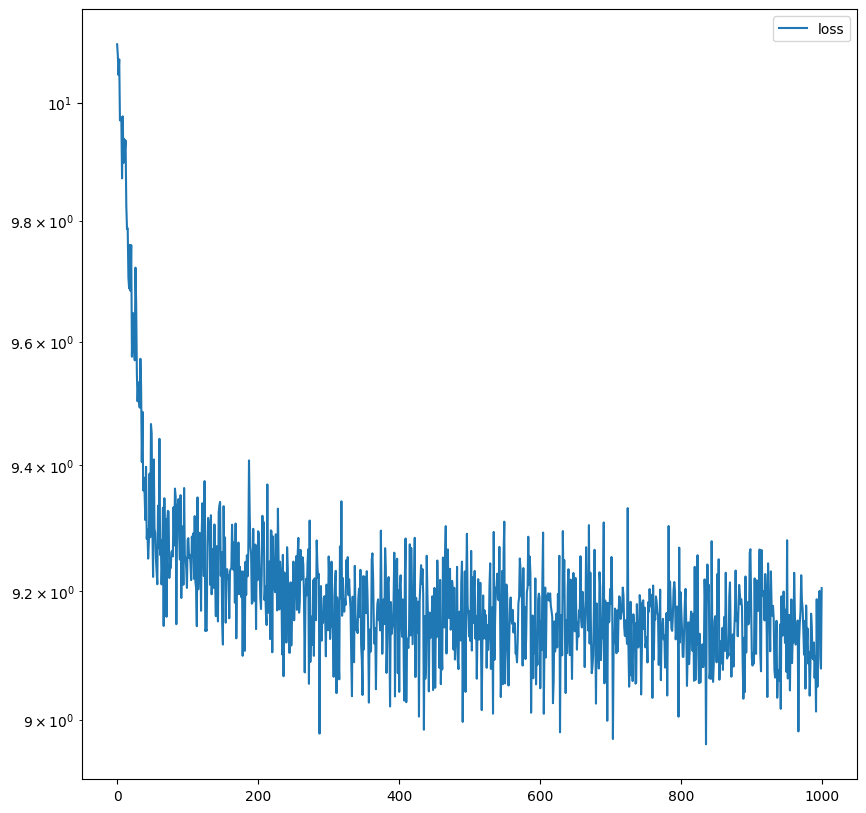

In [12]:
# Train model

iterations = 1000
num_samples = 2 ** 12

num_training_plots = 10
plot_every = int(iterations / num_training_plots if num_training_plots > 0 else iterations + 1)

loss_hist = np.array([])


clip_grad = True
clip_max_norm = 10


optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)


iterator = tqdm.tqdm(range(iterations))
for it in iterator:
    optimizer.zero_grad()

    batch = torch.rand((num_samples, 2), device = device) * 2 - 1

    # batch = model.prior.sample(num_samples)
    
    log_probs_q = model.prior.log_prob(batch)
    probs_q = torch.exp(log_probs_q)

    loss = model.compute_batch_gradient(target, batch, probs_q, 0.25)

    for p in model.parameters():
        p.grad = torch.nan_to_num(p.grad)

    loss_hist = np.append(loss_hist, loss.to('cpu').data.numpy())


    if clip_grad:
        ### Network and Encoding clipping
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=clip_max_norm)

    optimizer.step()
        
    
    if (it != 0 or plot_every < iterations) and it % plot_every == 0: 
        fig = model.visualize(target, num_samples=250000)
        plt.show()


fig = model.visualize(target, num_samples=1000000)
plt.show()

plt.figure(figsize=(10, 10))
plt.semilogy(loss_hist, label='loss')
plt.legend()
plt.show()

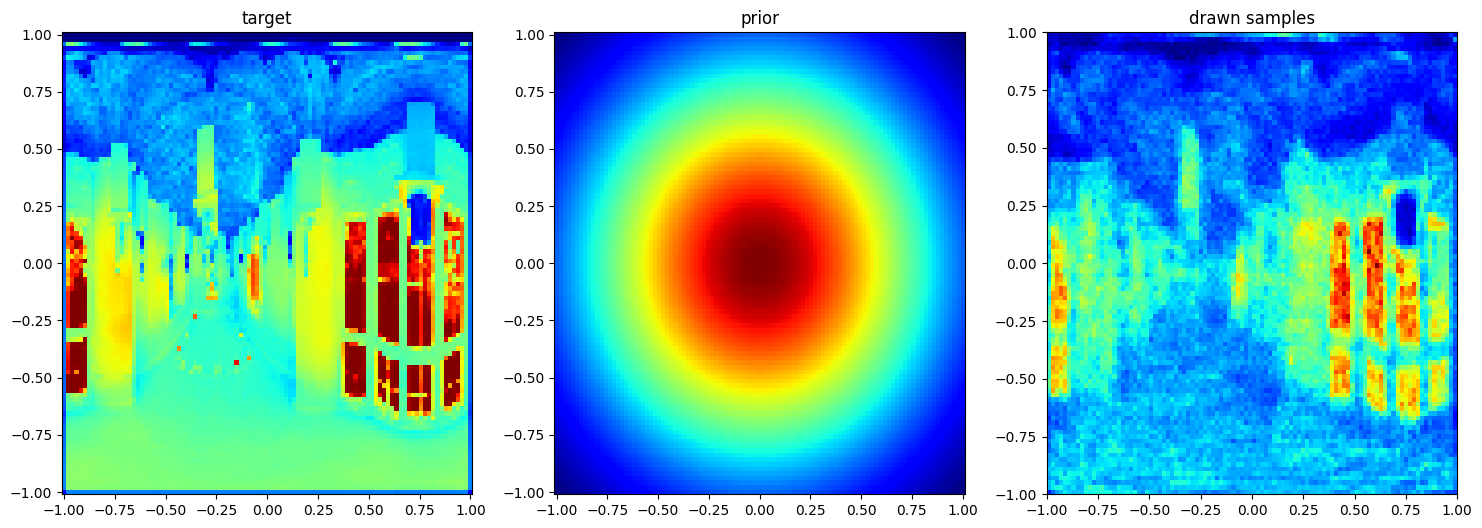

In [13]:
fig = model.visualize(target, num_samples=5000000)
plt.show()


# Naive Test

using device: cuda


C:\Users\janlu\AppData\Local\Temp\ipykernel_5740\682705650.py:22: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


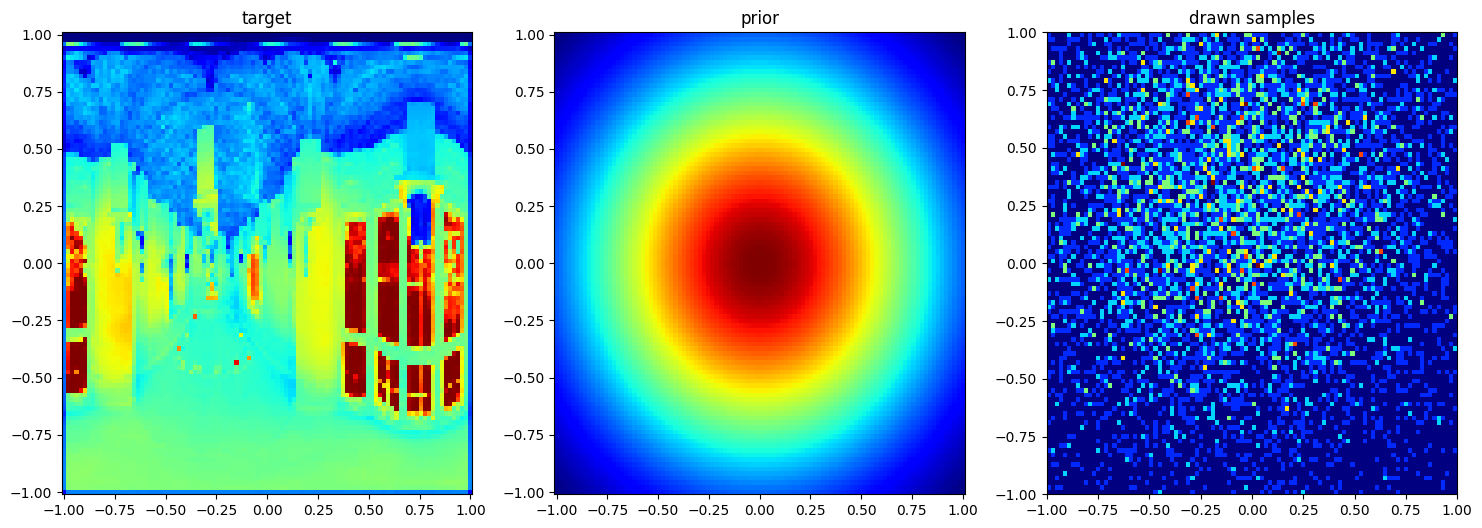

In [43]:
enable_cuda = True
device = torch.device('cuda' if torch.cuda.is_available() and enable_cuda else 'cpu')

# domain = torch.as_tensor([[0, torch.pi * 2], [0, torch.pi]])
domain = torch.as_tensor([[-1, 1], [-1, 1]])
means = (domain[:, 1] + domain[:, 0]) / 2
stds = (domain[:, 1] - domain[:, 0]) / (torch.pi) #) * 2)

prior = get_default_prior(means, stds)
encoding = get_default_encoding(device)
hidden_layers = [16, 16, 16]

model: models.AbstractModel = models.NaiveForwardModel(2, prior, encoding, hidden_layers, domain=domain)
target = get_default_target(domain = domain)


model.to(device)
target.to(device)
print(f"using device: {device}")

fig = model.visualize(target)
fig.show()

  0%|          | 0/10000 [00:00<?, ?it/s]

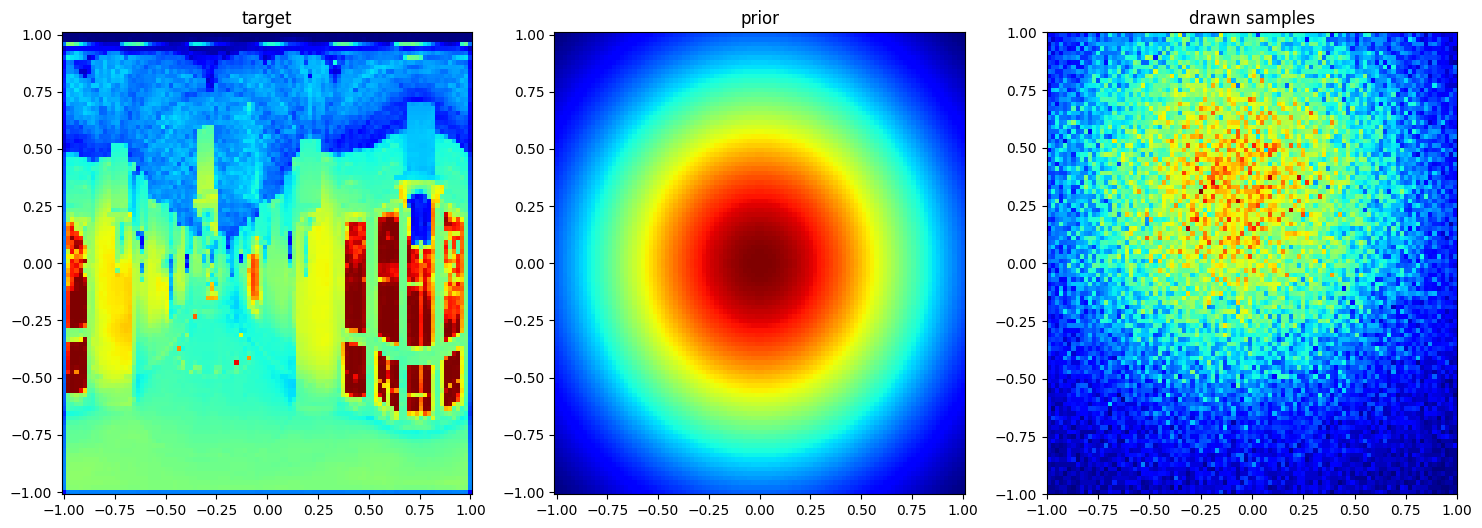

 10%|▉         | 999/10000 [01:08<10:13, 14.67it/s]

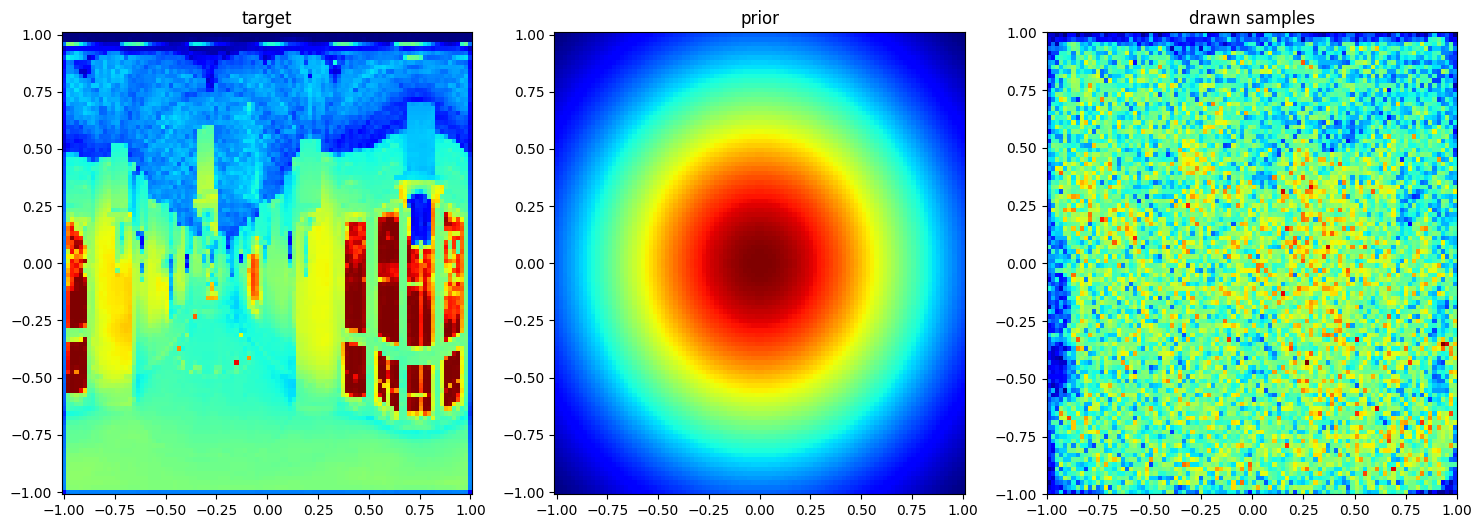

 20%|█▉        | 1999/10000 [02:16<08:54, 14.98it/s]

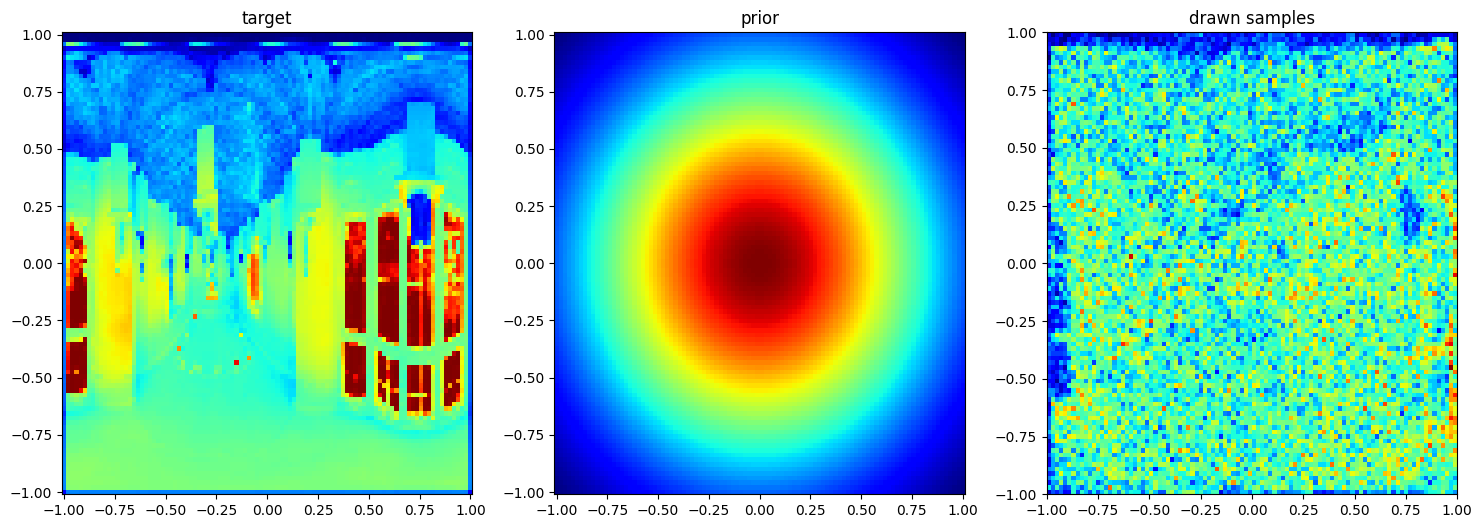

 30%|██▉       | 2999/10000 [03:26<07:48, 14.93it/s]

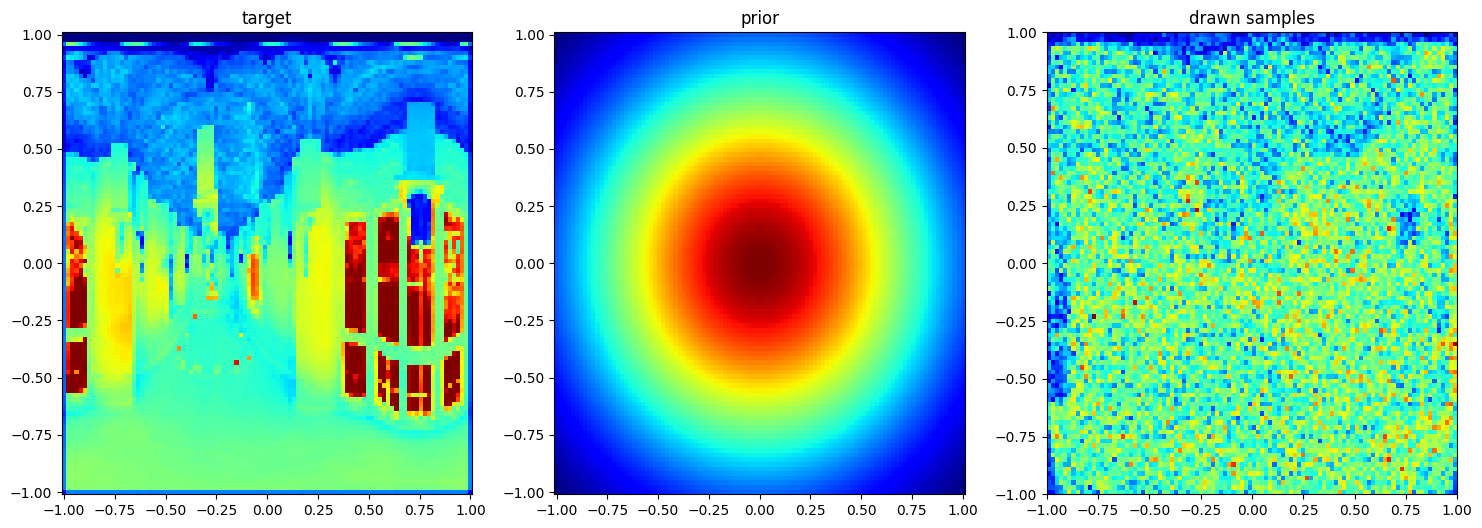

 40%|███▉      | 3999/10000 [04:34<06:27, 15.50it/s]

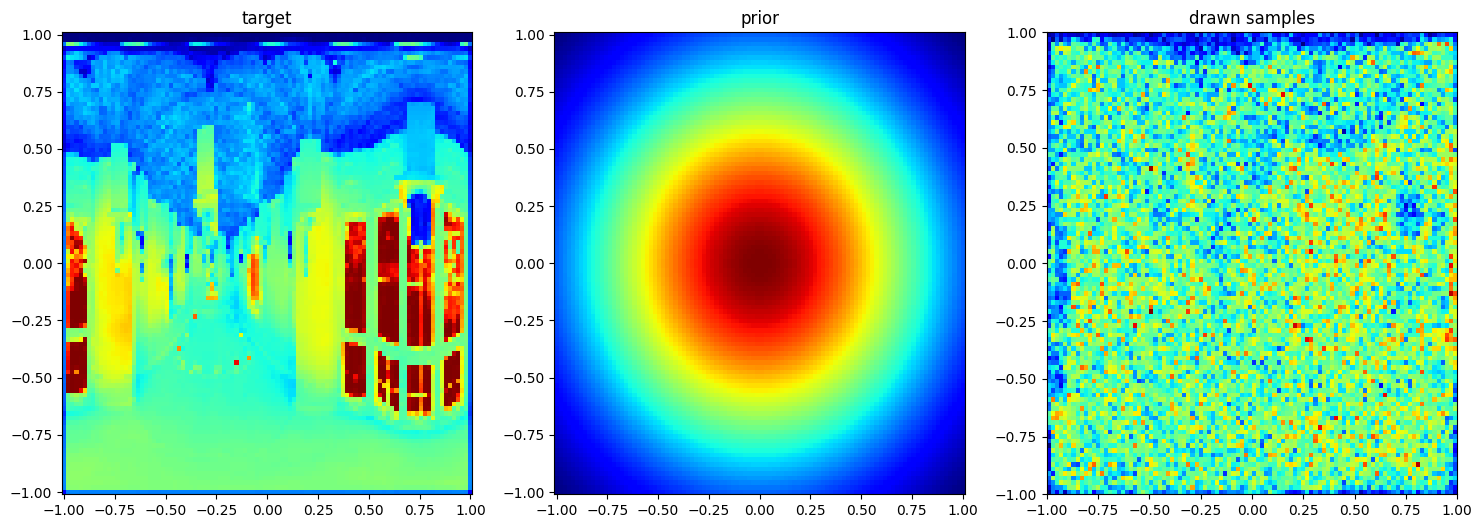

 50%|████▉     | 4999/10000 [05:40<06:07, 13.61it/s]

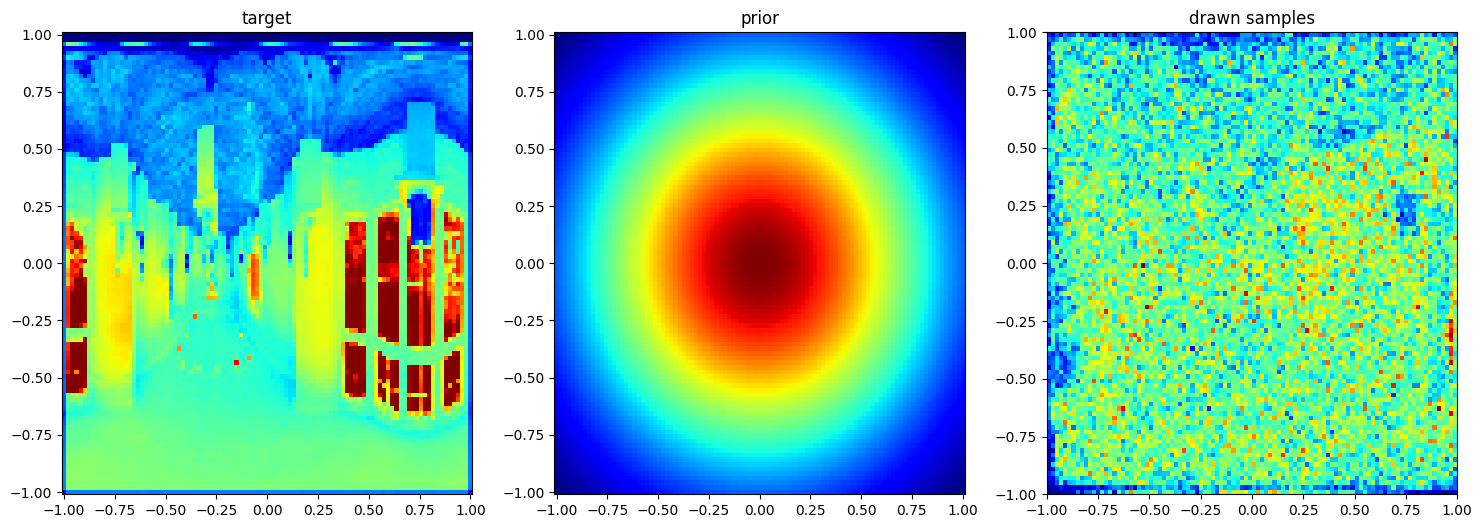

 60%|█████▉    | 5999/10000 [06:48<04:36, 14.46it/s]

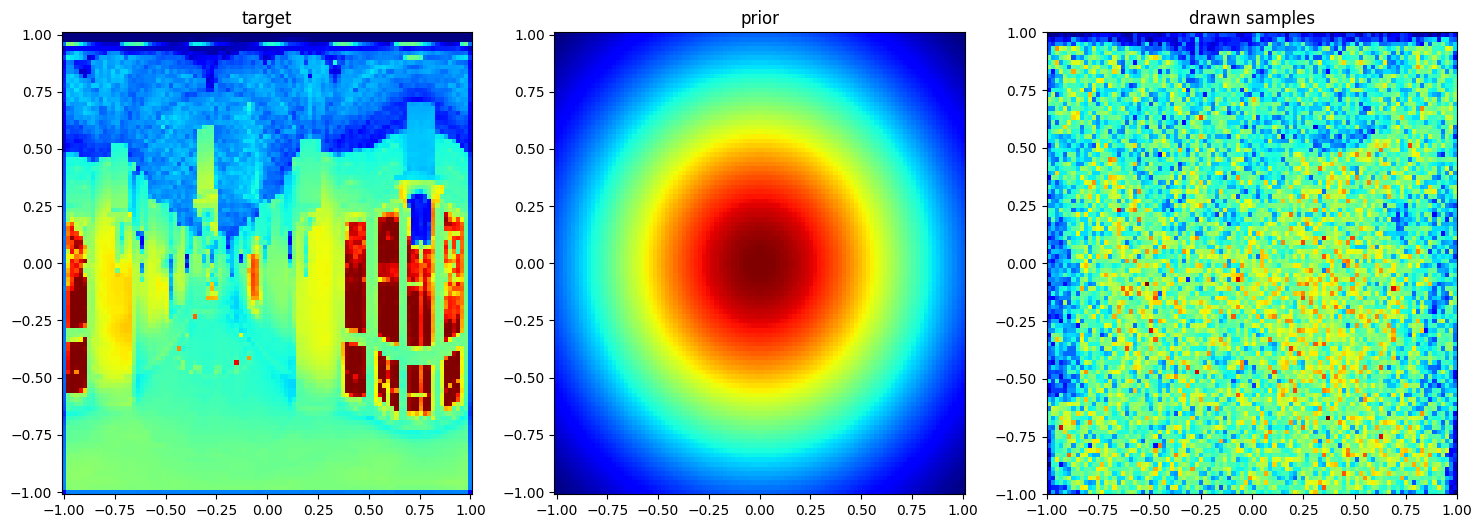

 70%|██████▉   | 6999/10000 [07:54<03:18, 15.10it/s]

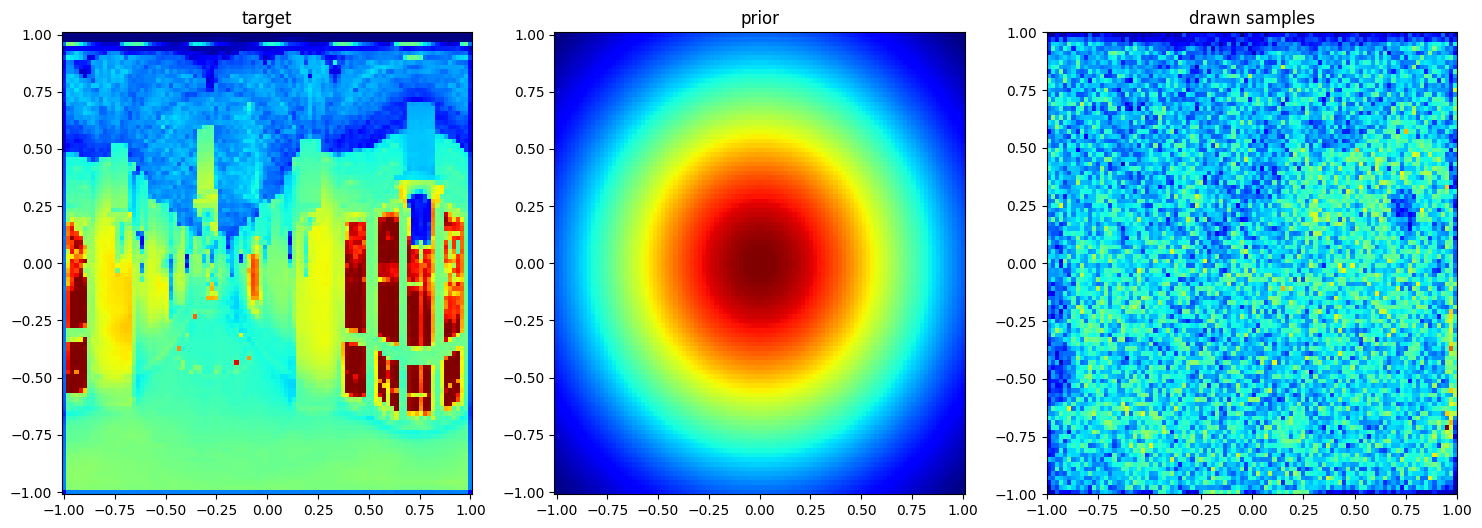

 80%|███████▉  | 7999/10000 [09:00<02:08, 15.58it/s]

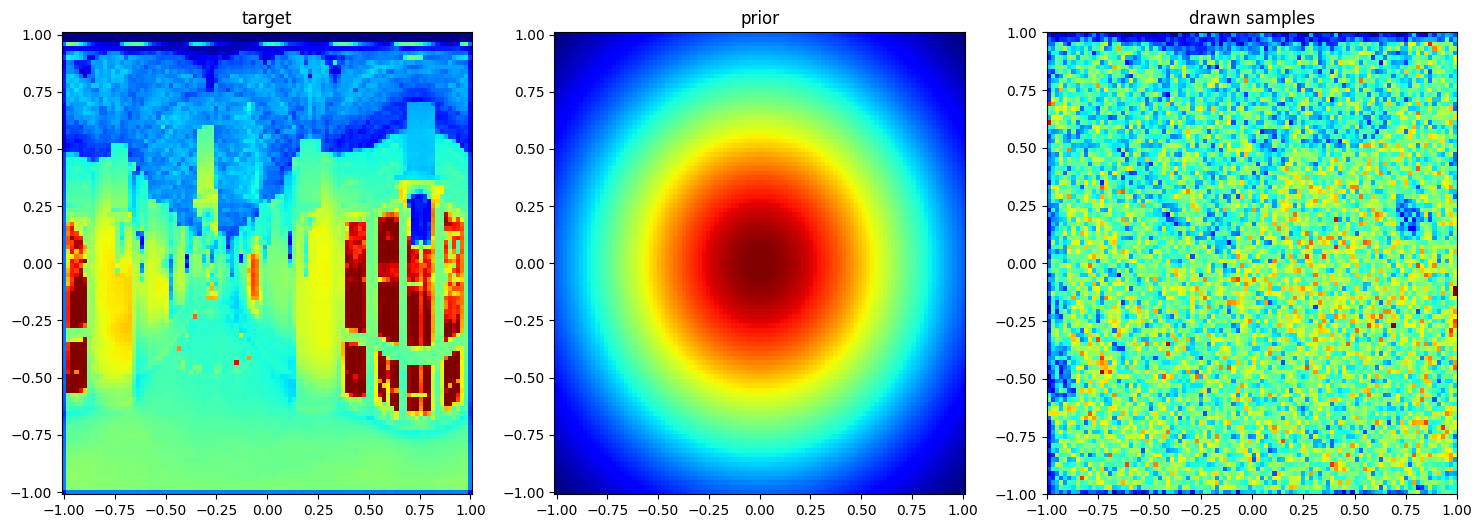

 90%|████████▉ | 8999/10000 [10:05<01:04, 15.49it/s]

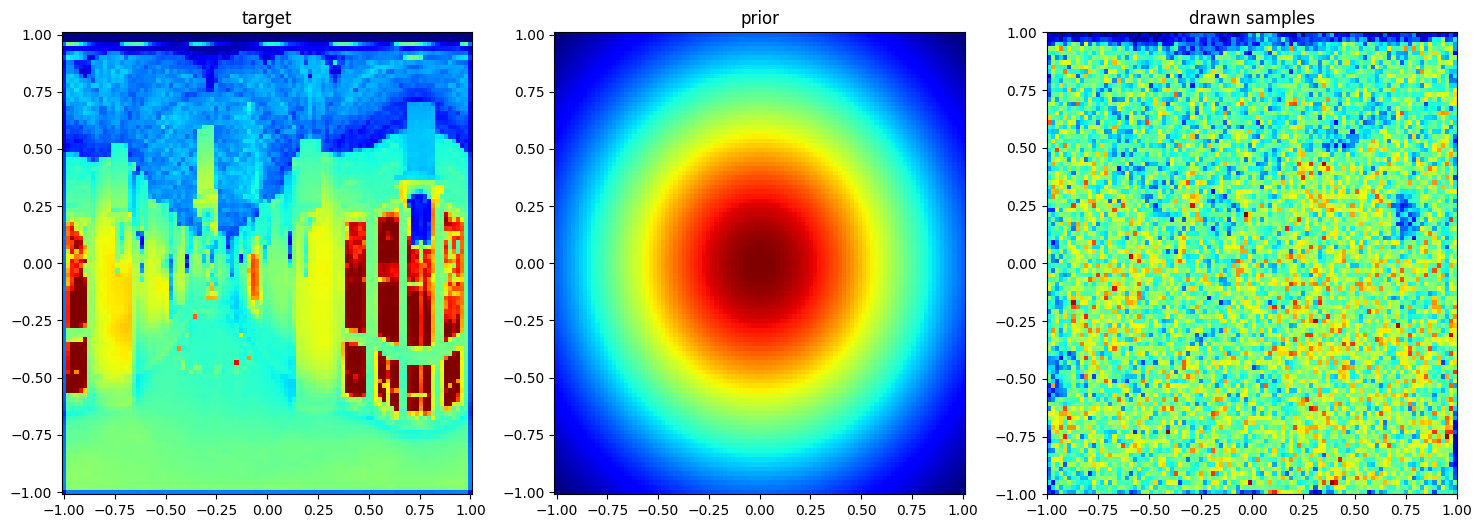

100%|██████████| 10000/10000 [11:10<00:00, 14.91it/s]


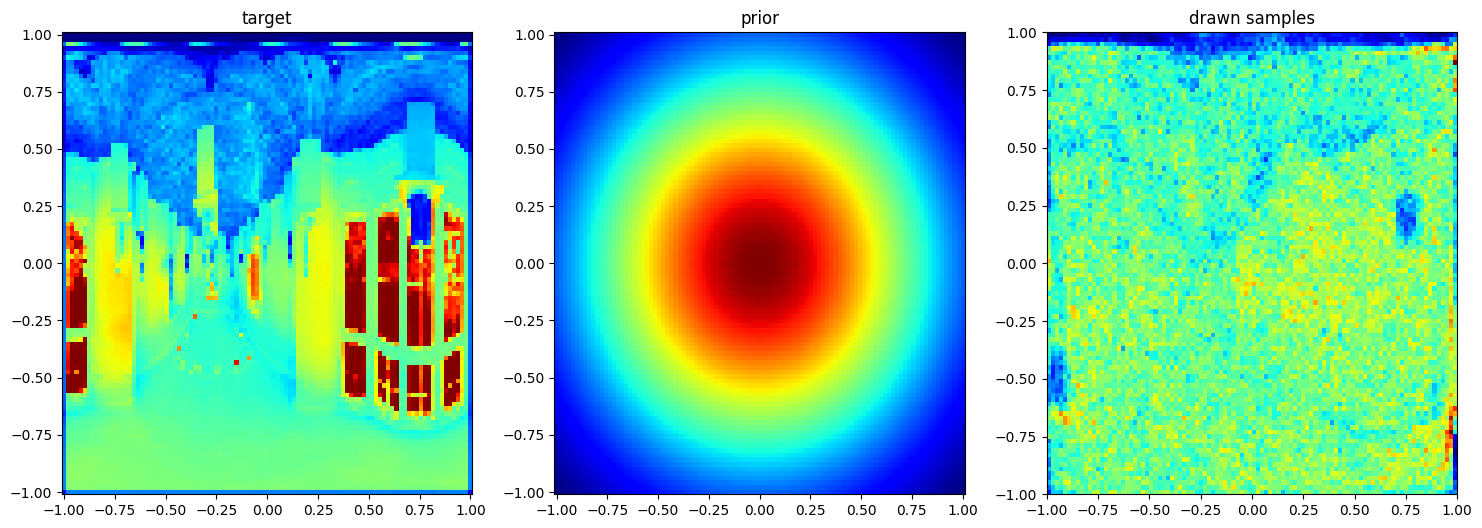

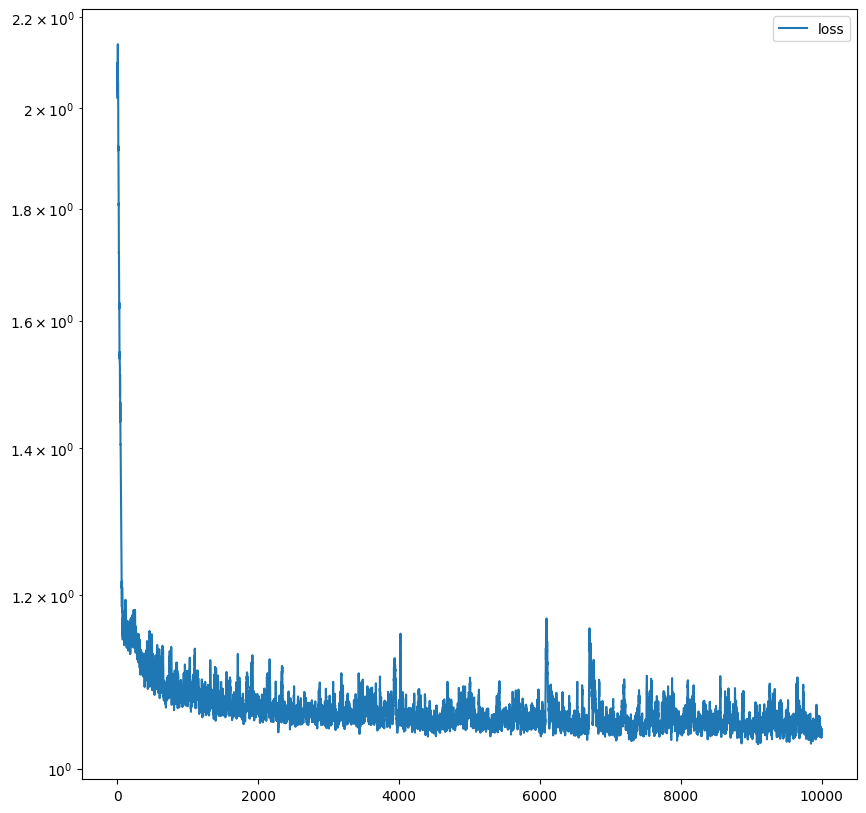

In [44]:
# Train model

iterations = 10000
num_samples = 2 ** 12

num_training_plots = 10
plot_every = int(iterations / num_training_plots if num_training_plots > 0 else iterations + 1)

loss_hist = np.array([])


clip_grad = True
clip_max_norm = 10


optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)


iterator = tqdm.tqdm(range(iterations))
for it in iterator:
    optimizer.zero_grad()

    batch = torch.rand((num_samples, 2), device = device) * 2 - 1

    # batch = model.prior.sample(num_samples)
    
    log_probs_q = model.prior.log_prob(batch)
    probs_q = torch.exp(log_probs_q)

    loss = model.compute_batch_gradient(target, batch, probs_q, 0.25)

    for p in model.parameters():
        p.grad = torch.nan_to_num(p.grad)

    loss_hist = np.append(loss_hist, loss.to('cpu').data.numpy())


    if clip_grad:
        ### Network and Encoding clipping
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=clip_max_norm)

    optimizer.step()
        
    
    if (it != 0 or plot_every < iterations) and it % plot_every == 0: 
        fig = model.visualize(target, num_samples=250000)
        plt.show()


fig = model.visualize(target, num_samples=1000000)
plt.show()

plt.figure(figsize=(10, 10))
plt.semilogy(loss_hist, label='loss')
plt.legend()
plt.show()

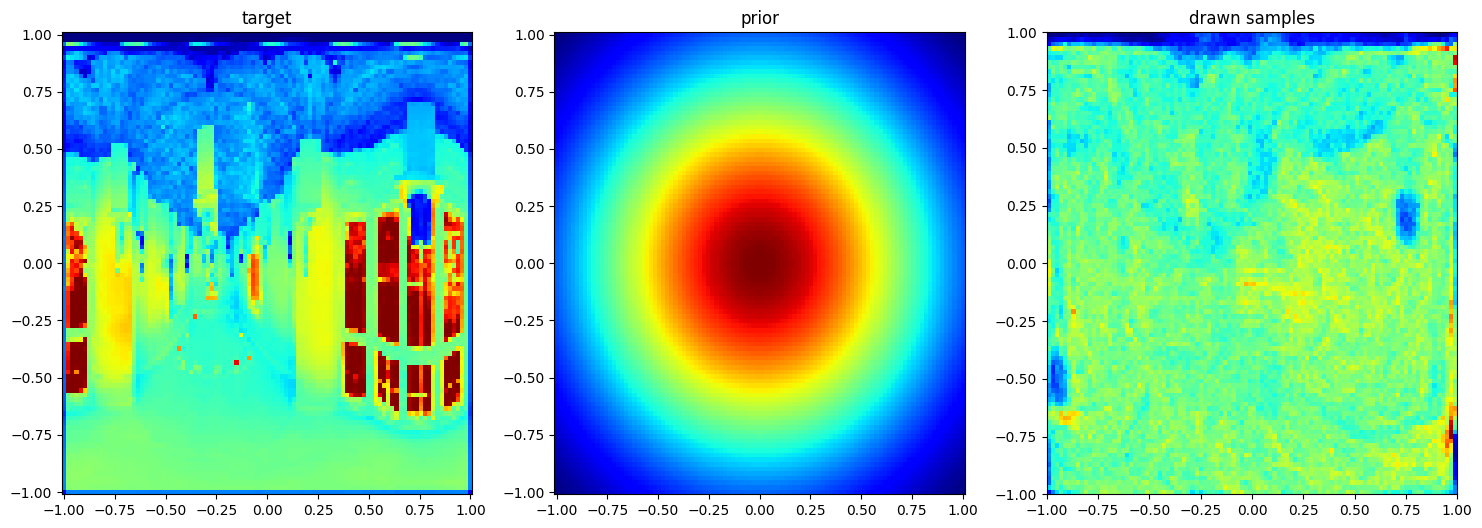

In [47]:
fig = model.visualize(target, num_samples=5000000)
plt.show()


# Spherical Coordinates test


In [5]:
def sign_nonzero(x):
    # Need a sign function where sign(0) = 1, otherwise when transforming 3d vectors to spherical coords
    # the vectors [1, 0, 0] and [-1, 0, 0] get the same angle
    return torch.where(x >= 0, torch.ones_like(x), -torch.ones_like(x))


def spherical_from_3d(v: torch.Tensor, as_lat: bool = True):
    """
    Computes the polar and azimuth angle of the given 3d vector.
    
    Arguments:
        v (torch.Tensor): tensor of vectors. requires v.shape[-1] ==  3
        as_lat (bool, optional): if True, the equator will have a polar angle of 0, otherwise v = (0, 0, 1) will have 0 polar angle

    """
    if type(v) is np.ndarray:
        v = torch.from_numpy(v)

    if not torch.is_floating_point(v):
        v = v.type(torch.float32)

    torch._assert(v.shape[-1] == 3, "Can only convert torch tensors with 3 elements in last dimension")

    v = torch.nn.functional.normalize(v, dim = -1)

    polar = torch.asin(v[..., 2]) if as_lat else torch.acos(v[..., 2])
    x = v[..., 0]
    y = v[..., 1]

    
    azimuth = torch.where((x != 0) | (y != 0), torch.acos(x / (x.square() + y.square()).sqrt()) * sign_nonzero(y), 0)

    return torch.stack((azimuth, polar), dim = -1)

def spherical_to_3d(v: torch.Tensor, as_lat: bool = True):
    """
    Computes a direction from a given azimuth and polar angle
    
    Arguments:
        v (torch.Tensor): tensor of angles. requires v.shape[-1] == 2, with v[..., 0] being the azimuth and v[..., 1] he polar angle
        as_lat (bool, optional): if True, the equator will have a polar angle of 0, otherwise v = (0, 0, 1) will have 0 polar angle

    """
    if type(v) is np.ndarray:
        v = torch.from_numpy(v)

    if not torch.is_floating_point(v):
        v = v.type(torch.float32)

    torch._assert(v.shape[-1] == 2, "Can only convert torch tensors with 3 elements in last dimension")

    polar = v[..., 1]
    z =                 torch.sin(polar) if as_lat else torch.cos(polar)
    xy_norm_factor =    torch.cos(polar) if as_lat else torch.sin(polar)

    azimuth = v[..., 0]
    x = torch.cos(azimuth) * xy_norm_factor
    y = torch.sin(azimuth) * xy_norm_factor

    return torch.stack((x, y, z), dim = -1)


def uniform_sphere(num_samples, device='cpu'):
    t = torch.randn((num_samples, 3), device = device)
    return spherical_from_3d(t)

In [6]:
def vis2dModel_spherical(model,
               target, 
               prior,
               device,
               grid_size = 100,
               num_test_samples = 1000, 
               start = -2, 
               end = 2, 
               num_samples = 10000):

    step = (end - start) / num_test_samples

    xx, yy = torch.meshgrid(torch.linspace(0, 1, grid_size), torch.linspace(0, 1, grid_size))
    zz = torch.cat([xx.unsqueeze(2), yy.unsqueeze(2)], 2).view(-1, 2)
    zz = zz.to(device)
    log_prob = target.log_prob(zz).to('cpu').view(*xx.shape)
    prob = torch.exp(log_prob)

    q=prior.log_prob(zz).exp().cpu().view(*xx.shape)
    
    jac = torch.func.vmap(torch.func.jacrev(model, chunk_size=1))
    jac_matrices = jac(zz)
    abs_dets = torch.det(jac_matrices).abs()

    transform_vecs = model(zz)
    transform = spherical_from_3d(transform_vecs)
    
    reconstruced_prior = abs_dets * target.log_prob(transform).exp()

     
    fig, (ax1, ax2, ax3, ax4) = plt.subplots(1, 4, figsize=(20, 5))

    ax1.pcolormesh(xx, yy, prob)
    ax1.set_title("target")
    
    ax2.pcolormesh(xx, yy, q)
    ax2.set_title("prior")

    ax3.pcolormesh(xx, yy, abs_dets.cpu().detach().view(*xx.shape))
    ax3.set_title("abs dets")

    # ax3.pcolormesh(xx, yy, reconstruced_prior.cpu().detach().view(*xx.shape))
    # ax3.set_title("reconstructed prior")
            
    x = prior.sample(num_samples)
    pred_samples = model(x).cpu().detach().numpy()
    ax4.hist2d(pred_samples[:, 0], pred_samples[:, 1], bins=100, range=[[0.0, 1.0], [0.0, 1.0]], cmap = 'viridis', norm="linear")
    ax4.set_title("drawn samples")
    
    return fig

def batched_dot(z):
    return torch.bmm(z.unsqueeze(1), z.unsqueeze(2))[:, 0, 0]

def I(z):
    return torch.divide(z, (batched_dot(z) + 1).sqrt().unsqueeze(-1))

def I_abs_det(z):
    return 1 / (batched_dot(z) + 1).square()

In [9]:
# img = plt.imread('assets/test_distributions/complex.png')
img = plt.imread('../assets/test_distributions/TestTargetDist.png')
target = nf.distributions.ImagePrior(img, x_range=[-np.pi, np.pi], y_range=[-np.pi / 2, np.pi / 2])

model = MLP(in_features=3, out_features=3, hidden_layers=[128, 128, 128], activation_function=nn.SiLU())

enable_cuda = True
device = torch.device('cuda' if torch.cuda.is_available() and enable_cuda else 'cpu')

q0 = nf.distributions.DiagGaussian((3), trainable=False)

target.to(device)
model.to(device)
q0.to(device)

vis2dModel_spherical(model=model, target=target, prior=q0, device=device).show()

RuntimeError: The size of tensor a (2) must match the size of tensor b (3) at non-singleton dimension 1

In [ ]:
# Train model
max_iter = 1000
num_samples = 2 ** 12
show_iter = 500

grid_size = 100

loss_hist = np.array([])

jac = torch.func.vmap(torch.func.jacrev(model, chunk_size=1))

alpha = 1e-3
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)

base_dist = torch.distributions.Normal(loc = 0, scale = 1)

for it in tqdm.tqdm(range(max_iter)):
    optimizer.zero_grad()

    z = q0.sample(num_samples)
    
    jac_matrices = jac(z)
    abs_dets = torch.det(jac_matrices).clamp(min = 1e-4)

    vecs = model(z)
    y = spherical_from_3d(vecs)
    probs_f = target.log_prob(y).exp()

    Is = I(z)
    probs_I = target.log_prob(Is).exp()

    dets_I = I_abs_det(z)

    f_loss = (1 - alpha) * probs_f * abs_dets
    I_loss =      alpha  * probs_I * dets_I

    losses = -torch.log(f_loss + I_loss)
    loss = torch.mean(losses[~(torch.isnan(losses) | torch.isinf(losses))])
    
    if ~(torch.isnan(loss) | torch.isinf(loss)):
        loss.backward()
        optimizer.step()
        
        loss_hist = np.append(loss_hist, loss.to('cpu').data.numpy())

    if it % show_iter == 0 and it > 0:
        pass
        vis2dModel_spherical(model=model, target=target, prior=q0, device=device).show()

vis2dModel_spherical(model=model, target=target, prior=q0, device=device).show()

plt.figure(figsize=(10, 10))
plt.semilogy(loss_hist, label='loss')
plt.legend()
plt.show()

# Simpler test case

Try to get their 1d examples working

In [4]:
enable_cuda = True
device = torch.device('cuda' if torch.cuda.is_available() and enable_cuda else 'cpu')


tensor(1., device='cuda:0')


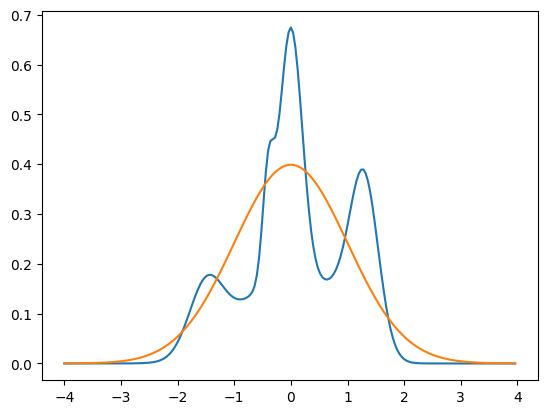

In [14]:
means = torch.tensor([-1.5, -0.7, -0.4, 0, 0.1, 0.9, 1.3], device = device)
sigmas = torch.tensor([0.3, 0.6, 0.1, 0.2, 0.5, 0.4, 0.25], device = device)
weights = torch.tensor([2, 3, 1, 5, 3, 2, 4], device=device)


sigmas_squared = sigmas.square()
weights = torch.divide(weights, weights.sum())



def eval_gaussian(x, means, sigmas_squared, weights):
    # x = torch.round(x, decimals=0)
    diff_squared = (x.unsqueeze(-1) - means).squeeze(0).square()
    exponent = -0.5 * diff_squared / sigmas_squared
    norm_factor = 1 / torch.sqrt(2 * torch.pi * sigmas_squared)

    individal_pdf = weights * norm_factor * torch.exp(exponent)
    return individal_pdf.sum(dim = 1)

def target(x, k = 10.0):
    return eval_gaussian(x, means, sigmas_squared, weights)
    # floor = eval_gaussian(torch.floor(x), means, sigmas_squared, weights)
    # ceil  = eval_gaussian(torch.ceil(x), means, sigmas_squared, weights)
# 
    # t = torch.frac(x)
# 
    # t = torch.where(t < 0, 1 + t, t)
# 
    # return (1 - t) * floor + t * ceil

    # return (-0.5 * x + 1) * torch.sigmoid(k * x) * torch.sigmoid(k * (2 - x))
    
    # mask = (x >= 0) & (x <= 2)
    # return torch.where(mask, -0.5 * x + 1, torch.full_like(fill_value=1e-4, input=x))

    # return torch.where((x < 0), torch.exp(x) / 3, 2 * torch.exp(-x) / 3)


prior_mean = torch.tensor([0], device = device)
prior_sigma = torch.tensor([1], device = device)
def prior(x):
    return (1 / torch.sqrt(2 * torch.pi * prior_sigma * prior_sigma) * torch.exp(- (x - prior_mean) ** 2 / (2 * (prior_sigma ** 2))))


start = -4
end = 4
num_sample_points = 200
step = (end - start) / num_sample_points

x = torch.arange(start, end, step=step, device = device)
prior_y = prior(x)
y = target(x)

print(y.sum() * step)

plt.plot(x.cpu(), y.cpu())
plt.plot(x.cpu(), prior_y.cpu())

In [15]:
def plot1dmodel(model, 
                device,
                num_test_samples = 1000, 
                start = -2, 
                end = 2, 
                plot_target = True, 
                plot_prior = True, 
                plot_prior_rec = True,
                plot_transform = False, 
                plot_model_reparam = False,
                include_samples = False,
                num_samples = 10000):

    step = (end - start) / num_test_samples

    x_lin = torch.arange(start, end, step, device = device)
    y = target(x_lin)
    p = prior(x_lin)

    jac = torch.func.vmap(torch.func.jacrev(model, chunk_size=1))


    jac_matrices = jac(x_lin.unsqueeze(-1))
    abs_dets = torch.det(jac_matrices)

    model_pdf = abs_dets * p

    transform = model(x_lin.unsqueeze(-1))
    reconstruced_prior = abs_dets * target(transform.squeeze(-1))

    if include_samples:
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))
    else:
        fig, ax1 = plt.subplots(1, 1, figsize=(10, 10))

    x_lin = x_lin.cpu()
    if plot_target: 
        ax1.plot(x_lin, y.cpu(), label = "target")
    
    if plot_prior: 
        ax1.plot(x_lin, p.cpu(), label = "prior")
    
    if plot_model_reparam:
        ax1.plot(x_lin, model_pdf.cpu().detach(), label = "model reparam")
    
    if plot_prior_rec:
        ax1.plot(x_lin, reconstruced_prior.cpu().detach(), label = "reconstructed prior")
    
    if plot_transform:
        ax1.plot(x_lin, transform.cpu().detach(), label = "transformed x axis")
        
    if include_samples:
        x = torch.randn(num_samples, device = device)
        pred_samples = model(x.unsqueeze(-1)).cpu().detach().numpy()
        plt.hist(pred_samples, bins=100)

    fig.legend()
    return fig
    # fig.show()

In [16]:
model_1d = MLP(in_features=1, out_features=1, hidden_layers=[16, 16, 16], activation_function=nn.SiLU())
model_1d.to(device)
# model_1d.apply(init_identity)

MLP(
  (in_proj): Layer(
    (lin_forward): Linear(in_features=1, out_features=16, bias=True)
    (activation): SiLU()
  )
  (net): Sequential(
    (0): Layer(
      (lin_forward): Linear(in_features=16, out_features=16, bias=True)
      (activation): SiLU()
    )
    (1): Layer(
      (lin_forward): Linear(in_features=16, out_features=16, bias=True)
      (activation): SiLU()
    )
  )
  (out_proj): Linear(in_features=16, out_features=1, bias=True)
)

100%|██████████| 1000/1000 [00:08<00:00, 114.27it/s]
C:\Users\janlu\AppData\Local\Temp\ipykernel_12044\3781411113.py:51: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


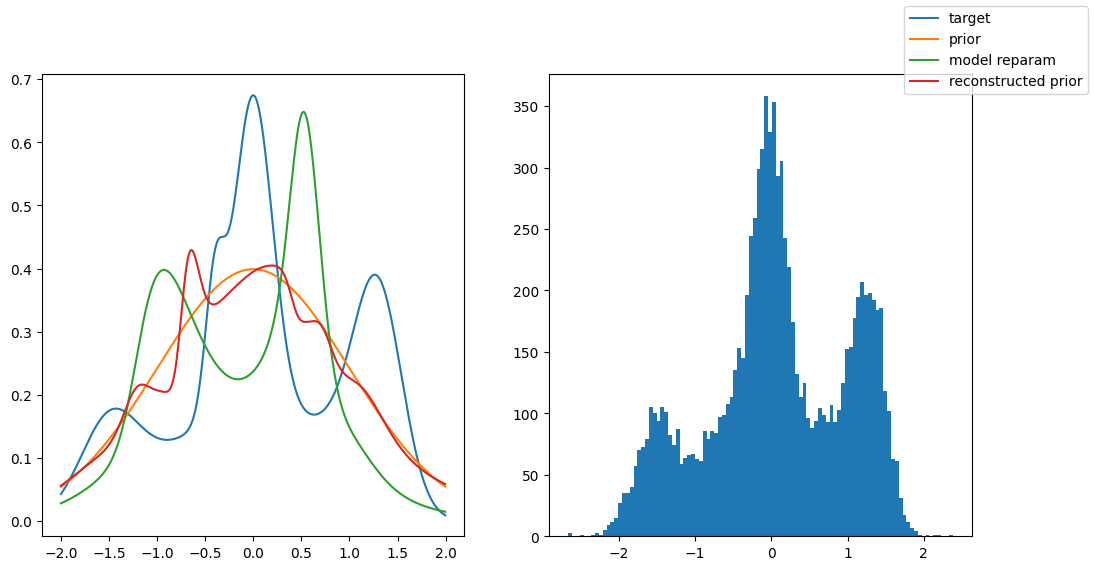

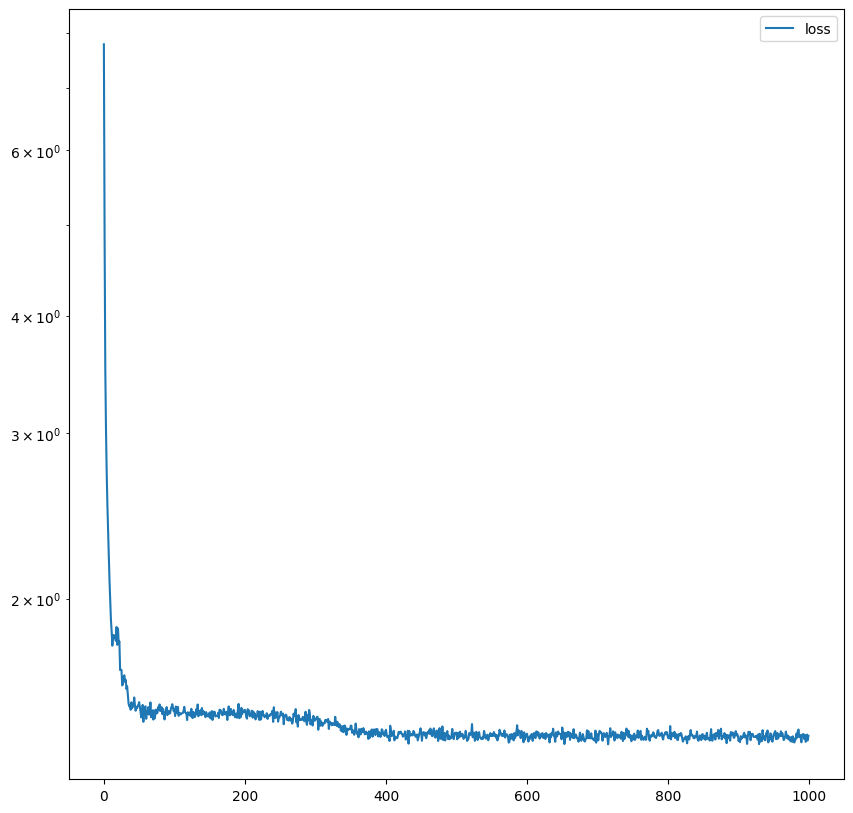

In [17]:
# Train model
max_iter = 1000
num_samples = 2 ** 12
show_iter = 10000

grid_size = 100

loss_hist = np.array([])

jac = torch.func.vmap(torch.func.jacrev(model_1d, chunk_size=1))

alpha = 1e-3
optimizer = torch.optim.AdamW(model_1d.parameters(), lr=1e-2, weight_decay=1e-4)

base_dist = torch.distributions.Normal(loc = 0, scale = 1)

for it in tqdm.tqdm(range(max_iter)):
    optimizer.zero_grad()

    # x = torch.rand((num_samples, 2), device=device)
    z = torch.randn(num_samples, device = device)
    log_probs_z = base_dist.log_prob(z)
    probs_q = torch.exp(log_probs_z)
    
    jac_matrices = jac(z.unsqueeze(-1))
    abs_dets = torch.det(jac_matrices).clamp(min = 1e-4, max = 1e3)

    y = model_1d(z.unsqueeze(-1)).squeeze(-1)
    probs_f = target(y)

    Is = z / (z.square() + 1).sqrt()
    probs_I = target(Is)

    det_I = 1 / (z.square() + 1).square()

    f_loss = (1 - alpha) * probs_f * abs_dets
    I_loss =      alpha  * probs_I * det_I
    
    losses = -torch.log(f_loss + I_loss)
    loss = torch.mean(losses[~(torch.isnan(losses) | torch.isinf(losses))])

    if ~(torch.isnan(loss) | torch.isinf(loss)):
        loss.backward()
        optimizer.step()
        loss_hist = np.append(loss_hist, loss.to('cpu').data.numpy())

    if it % show_iter == 0 and it > 0:
        plot1dmodel(model_1d, device, plot_target=True, include_samples=True, plot_model_reparam=True).show()

fig = plot1dmodel(model_1d, device, plot_target=True, include_samples=True, plot_model_reparam=True)
fig.show()

plt.figure(figsize=(10, 10))
# plt.plot(loss_hist, label='loss')
plt.semilogy(loss_hist, label='loss')
plt.legend()
plt.show()

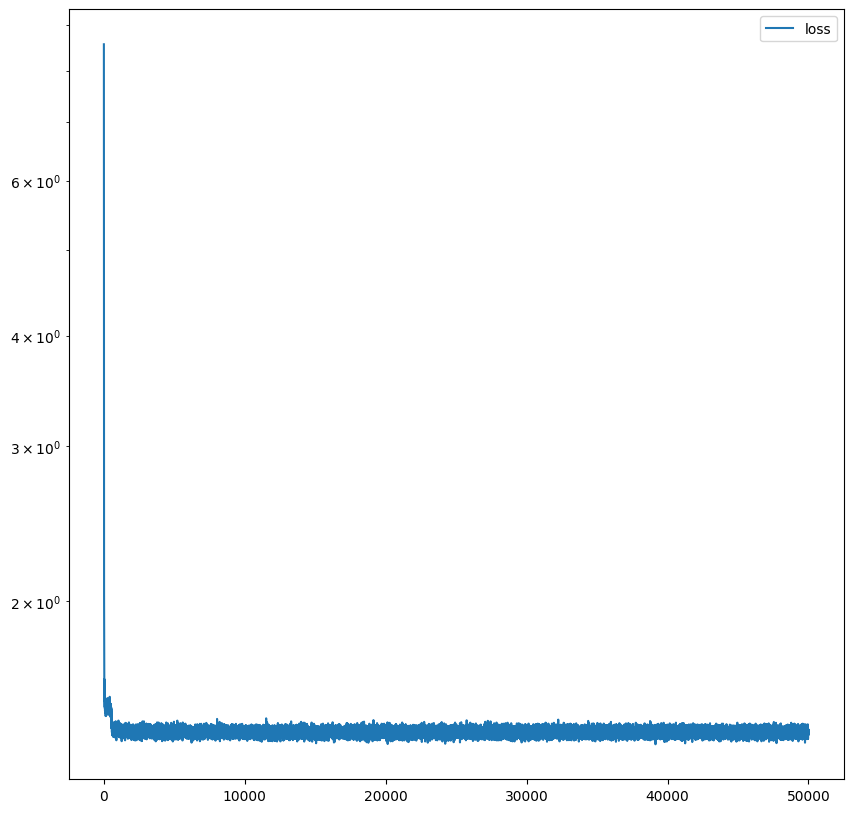

In [97]:
plt.figure(figsize=(10, 10))
# plt.plot(loss_hist, label='loss')
plt.semilogy(loss_hist, label='loss')
plt.legend()
plt.show()

## ToDo Ideas remaining for this 1d test

- Can I somehow use these values to recover the full pdf ?
- Can I Plot the actual jacobians (in 1d these are scalars, I might be able to plot them as functions)
    - Use abs() instead of clamp() and see if I can get a visual representation of where probability density is moved (directional, not just through the abs value in model reparam)
- What happens with long training for small models
- Can it learn discontinuities ?
    - Important learning:
        - It seems it can, but the infinite support is very important!
        - Some care also needs to taken if target function can be 0

C:\Users\janlu\AppData\Local\Temp\ipykernel_14496\2207190585.py:1: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plot1dmodel(model_1d, device, plot_target=True, include_samples=False, plot_model_reparam=True).show()


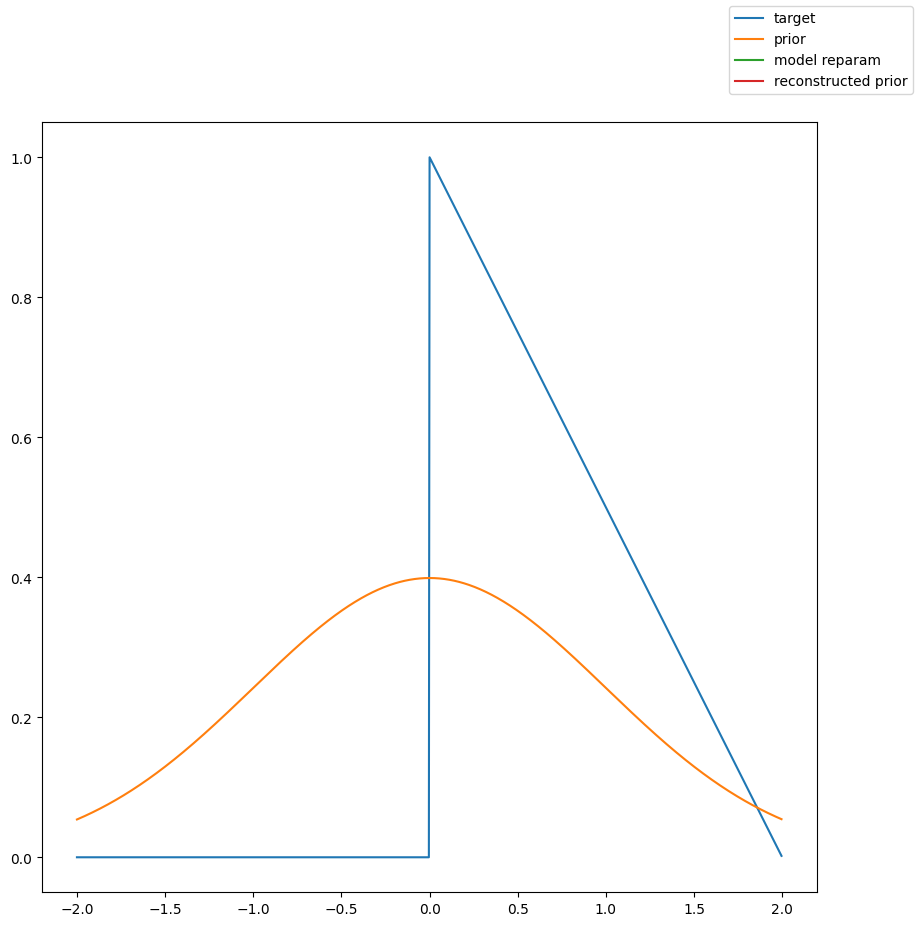

In [42]:
plot1dmodel(model_1d, device, plot_target=True, include_samples=False, plot_model_reparam=True).show()

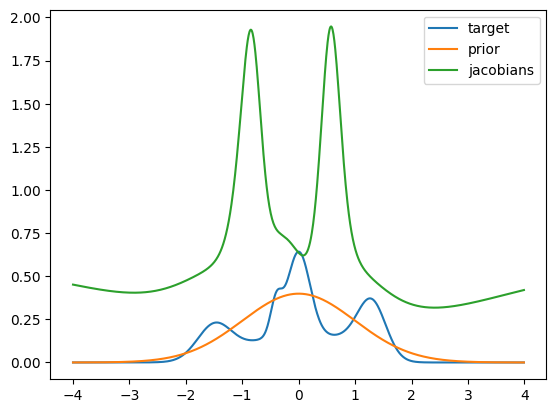

In [ ]:
def normalize_posterior(post, num_bins, start, end):
    norm_factor = (end - start) / num_bins
    return np.divide(post, norm_factor)

num_test_samples = 1000

step = (end - start) / num_test_samples

x_lin = torch.arange(start, end, step, device = device)
y = target(x_lin)
p = prior(x_lin)

jac = torch.func.vmap(torch.func.jacrev(model_1d, chunk_size=1))


jac_matrices = jac(x_lin.unsqueeze(-1))
dets = torch.det(jac_matrices)
abs_dets = dets.abs()

model_pdf = abs_dets * p

transform = model_1d(x_lin.unsqueeze(-1))
reconstruced_prior = abs_dets * target(transform.squeeze(-1))

x_lin = x_lin.cpu()
plt.plot(x_lin, y.cpu(), label = "target")
plt.plot(x_lin, p.cpu(), label = "prior")
plt.plot(x_lin, model_pdf.detach(), label = "model pdf")
# plt.plot(x_lin, reconstruced_prior.cpu().detach(), label = "reconstructed prior")
plt.plot(x_lin, jac_matrices[:, 0, 0].cpu().detach(), label = "jacobians")
plt.legend()
plt.show()